# MScFE 660 Risk Management: Group Work Project 1 (Steps 3 to 8)

### Setup

In [1]:
import os, re, json, time, hashlib, zipfile, textwrap, warnings
import datetime as dt
from pathlib import Path

import numpy as np
import pandas as pd
import requests
import yfinance as yf
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy import stats
from statsmodels.tsa.stattools import adfuller, kpss, acf
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tools.sm_exceptions import InterpolationWarning
from dotenv import load_dotenv

warnings.filterwarnings("ignore", category=InterpolationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 80)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW, CLEAN = ROOT / "data" / "raw", ROOT / "data" / "clean"
for d in [RAW / "fred", RAW / "eia", RAW / "gpr", RAW / "yahoo", CLEAN]:
    d.mkdir(parents=True, exist_ok=True)
load_dotenv(ROOT / ".env")
FRED_KEY, EIA_KEY = os.getenv("FRED_API_KEY"), os.getenv("EIA_API_KEY")
cat = pd.read_json(ROOT / "data" / "variables.json").set_index("key")
SHORT = cat["short_name"].to_dict()

def caption(fig, text, y=-0.01):
    fig.text(0.01, y, textwrap.fill(text, 190), ha="left", va="top", fontsize=7.5, color="grey")

## Step 3: Identify, import, structure and graph the variables

We started from Alvi's own variables: the fourteen EIA Short-Term Energy Outlook (STEO) series in his Table 3.1, the eight FRED series in his Table 3.2, the EIA import series `PET.MCRIMXX2.M` that appears in his code, and his target, the monthly WTI spot price `WTISPLC` (Alvi, 2018). We then added five items of our own: the Geopolitical Risk (GPR) index, daily WTI and Brent spot prices, NYMEX crude oil futures, a replacement for a discontinued FRED series, and the S&P 500 as a non-oil benchmark. We downloaded FRED data through the FRED API and EIA data through the EIA API v2, both with our keys, the GPR file from the authors' website and the daily market data from Yahoo Finance. Finally, we organised the series into monthly, daily and low-frequency tables and plotted every variable by category.

### 3.1 The variable set and its categories

We stored the variable set in `data/variables.json`: one entry per series with its ID, source, category, native frequency, origin, the change we use in the analysis, and a short label for charts.

**Table 3.1: The variable set** (frequency: M monthly, Q quarterly, A annual, D daily)

| ID | Series | Source | Category | Frequency | Origin | Change used |
|---|---|---|---|---|---|---|
| `INDPRO` | Industrial Production: Total Index | FRED | Macro/geopolitical | M | Alvi (2018), Table 3.2 | Log difference |
| `CPIENGSL` | CPI-U: Energy | FRED | Macro/geopolitical | M | Alvi (2018), Table 3.2 | Log difference |
| `STEO.PAPR_OPEC.M` | Total OPEC petroleum supply | EIA | Macro/geopolitical | M | Alvi (2018), Table 3.1 | Log difference |
| `STEO.COPC_OPEC.M` | OPEC crude oil production capacity | EIA | Macro/geopolitical | M | Alvi (2018), Table 3.1 | Log difference |
| `STEO.COPS_OPEC.M` | OPEC spare crude oil production capacity | EIA | Macro/geopolitical | M | Alvi (2018), Table 3.1 | First difference |
| `GPR` | Geopolitical Risk Index (Recent GPR) | GPR | Macro/geopolitical | M | Our addition | Log difference |
| `STEO.RGDPQ_OECD.A` | OECD real GDP index | EIA | Macro/geopolitical | A | Alvi (2018), Table 3.1 (as .M) | Log difference |
| `STEO.RGDPQ_NONOECD.A` | Non-OECD real GDP index | EIA | Macro/geopolitical | A | Alvi (2018), Table 3.1 (as .M) | Log difference |
| `STEO.FOREX_WORLD.Q` | U.S. dollar index | EIA | Macro/geopolitical | Q | Alvi (2018), Table 3.1 (as .M) | Log difference |
| `STEO.PAPR_NONOPEC.M` | Non-OPEC liquids production | EIA | Microeconomic | M | Alvi (2018), Table 3.1 | Log difference |
| `STEO.PATC_OECD.M` | OECD liquid fuels consumption | EIA | Microeconomic | M | Alvi (2018), Table 3.1 | Log difference |
| `STEO.PATC_NON_OECD.M` | Non-OECD liquid fuels consumption | EIA | Microeconomic | M | Alvi (2018), Table 3.1 | Log difference |
| `STEO.PASC_OECD_T3.M` | OECD commercial inventory | EIA | Microeconomic | M | Alvi (2018), Table 3.1 | Log difference |
| `STEO.T3_STCHANGE_OOECD.M` | Net inventory withdrawals, other OECD | EIA | Microeconomic | M | Alvi (2018), Table 3.1 | First difference |
| `STEO.T3_STCHANGE_NOECD.M` | Net inventory withdrawals, non-OECD | EIA | Microeconomic | M | Alvi (2018), Table 3.1 | First difference |
| `STEO.COPRPUS.M` | U.S. crude oil production | EIA | Microeconomic | M | Alvi (2018), Table 3.1 | Log difference |
| `STEO.CORIPUS.M` | U.S. crude oil refinery input | EIA | Microeconomic | M | Alvi (2018), Table 3.1 | Log difference |
| `PET.MCRIMXX2.M` | U.S. crude imports from OPEC | EIA | Microeconomic | M | Alvi (2018), code | Log difference |
| `CAPG211S` | Capacity: oil and gas extraction | FRED | Microeconomic | M | Alvi (2018), Table 3.2 | Log difference |
| `CAPUTLG211S` | Capacity utilization: oil and gas extraction | FRED | Microeconomic | M | Alvi (2018), Table 3.2 | First difference |
| `IPG211S` | IP: oil and gas extraction | FRED | Microeconomic | M | Alvi (2018), Table 3.2 | Log difference |
| `IPG211111CN` | IP: crude oil (discontinued) | FRED | Microeconomic | M | Alvi (2018), Table 3.2 | Log difference |
| `IPG21112S` | IP: crude oil (NAICS 21112) | FRED | Microeconomic | M | Our addition (B1) | Log difference |
| `IPN213111N` | IP: drilling oil and gas wells | FRED | Microeconomic | M | Alvi (2018), Table 3.2 | Log difference |
| `PCU211211` | PPI: oil and gas extraction | FRED | Microeconomic | M | Alvi (2018), Table 3.2 | Log difference |
| `WTISPLC` | WTI spot price (monthly) | FRED | Financial | M | Alvi (2018), target | Log difference |
| `DCOILWTICO` | WTI spot price, Cushing (daily) | FRED | Financial | D | Our addition | Log difference |
| `DCOILBRENTEU` | Brent spot price, Europe (daily) | FRED | Financial | D | Our addition | Log difference |
| `CL=F` | NYMEX crude oil futures, front month | Yahoo | Financial | D | Our addition | Log difference |
| `^GSPC` | S&P 500 index (benchmark) | Yahoo | Financial (benchmark) | D | Our addition (benchmark) | Log difference |
| `STEO.COPR_OPEC.M` | OPEC crude oil production | EIA | Diagnostic only | M | Diagnostic for B4 | Log difference |

**Interpretation.** Table 3.1 lists the 31 series we use. The categories follow the brief's definitions: macroeconomic data describe countries and governments, microeconomic data describe business and individual decisions, and financial data describe securities and markets. The split of oil supply is our judgement, based on Alvi's distinction between OPEC, which has a centralised decision-making body and consists mostly of national oil companies, and non-OPEC producers, which decide independently, are mostly investor-owned and act as price takers (Alvi, 2018). We therefore classed OPEC supply, capacity and spare capacity as macroeconomic or geopolitical, and non-OPEC supply, consumption, inventories and U.S. industry series as microeconomic.

Our additions are labelled in the `origin` column. We added the GPR index because Alvi has no direct geopolitical variable, although he names geopolitical events among the main drivers of the oil price (Alvi, 2018). The futures series ties to Alvi's question of how futures prices relate to the spot price (Alvi, 2018). The S&P 500 is used only as a benchmark in Step 8. `STEO.COPR_OPEC.M` (OPEC crude production) is a diagnostic series for the checks in Step 5 and is not a model variable.

### 3.2 Import

We wrote one request helper for all API calls. It retries on network errors and, when it fails, reports only the source and series, so the API keys never appear in the output. Every response is saved untouched, and a manifest records what was downloaded and when.

In [2]:
MANIFEST = RAW / "download_manifest.json"

def record(path, source, note=""):
    man = json.loads(MANIFEST.read_text()) if MANIFEST.exists() else {}
    data = Path(path).read_bytes()
    man[Path(path).relative_to(ROOT).as_posix()] = {
        "source": source, "downloaded_utc": dt.datetime.now(dt.timezone.utc).isoformat(timespec="seconds"),
        "bytes": len(data), "sha256": hashlib.sha256(data).hexdigest(), "note": note}
    MANIFEST.write_text(json.dumps(man, indent=1))

def api_get(url, params, label, tries=6):
    err = None
    for k in range(tries):
        try:
            r = requests.get(url, params=params, timeout=90)
            if r.status_code == 200:
                return r.content
            err = f"HTTP {r.status_code}"
        except requests.RequestException as e:
            err = type(e).__name__
        time.sleep(5 * (k + 1))
    raise RuntimeError(f"{label}: request failed ({err})")

def cached_json(path, url, params, label):
    path = Path(path)
    if not path.exists():
        path.write_bytes(api_get(url, params, label))
        record(path, label)
    return json.loads(path.read_text())

**FRED.** For each FRED series we requested the series metadata, its release, the release's source and the observations from the FRED API (Board of Governors of the Federal Reserve System, 2021, 2026a, 2026b, 2026c, 2026d, 2026e, 2026f; Federal Reserve Bank of St. Louis, 2026; U.S. Bureau of Labor Statistics, 2026a, 2026b; U.S. Energy Information Administration [EIA], 2026a, 2026b).

In [3]:
FRED = "https://api.stlouisfed.org/fred/"
fred_keys = cat.index[cat.source == "FRED"].tolist()
fred_raw = {}
for k in fred_keys:
    q = {"api_key": FRED_KEY, "file_type": "json", "series_id": k}
    series = cached_json(RAW / "fred" / f"{k}_series.json", FRED + "series", q, f"FRED series {k}")
    release = cached_json(RAW / "fred" / f"{k}_release.json", FRED + "series/release", q, f"FRED release {k}")
    rid = release["releases"][0]["id"]
    sources = cached_json(RAW / "fred" / f"{k}_sources.json", FRED + "release/sources",
                          {"api_key": FRED_KEY, "file_type": "json", "release_id": rid}, f"FRED sources {k}")
    obs = cached_json(RAW / "fred" / f"{k}_observations.json", FRED + "series/observations", q, f"FRED observations {k}")
    fred_raw[k] = {"series": series["seriess"][0], "release": release["releases"][0]["name"],
                   "source": "; ".join(s["name"] for s in sources["sources"]), "obs": obs["observations"]}

fred_meta = pd.DataFrame({k: {"title": v["series"]["title"], "units": v["series"]["units"],
                              "seasonal adj.": v["series"]["seasonal_adjustment_short"], "freq": v["series"]["frequency_short"],
                              "start": v["series"]["observation_start"], "end": v["series"]["observation_end"],
                              "source": v["source"], "release": v["release"]} for k, v in fred_raw.items()}).T
print("Table 3.2: FRED metadata returned by the API")
fred_meta

Table 3.2: FRED metadata returned by the API


,title,units,seasonal adj.,freq,start,end,source,release
INDPRO,Industrial Production: Total Index,Index 2017=100,SA,M,1919-01-01,2026-08-01,Board of Governors of the Federal Reserve System (US),G.17 Industrial Production and Capacity Utilization
CPIENGSL,Consumer Price Index for All Urban Consumers: Energy in U.S. City Average,Index 1982-1984=100,SA,M,1957-01-01,2026-08-01,U.S. Bureau of Labor Statistics,Consumer Price Index
CAPG211S,Industrial Capacity: Mining: Oil and Gas Extraction (NAICS = 211),Index 2017=100,SA,M,1972-01-01,2026-08-01,Board of Governors of the Federal Reserve System (US),G.17 Industrial Production and Capacity Utilization
CAPUTLG211S,Capacity Utilization: Mining: Oil and Gas Extraction (NAICS = 211),Percent,SA,M,1972-01-01,2026-08-01,Board of Governors of the Federal Reserve System (US),G.17 Industrial Production and Capacity Utilization
IPG211S,Industrial Production: Mining: Oil and Gas Extraction (NAICS = 211),Index 2017=100,SA,M,1972-01-01,2026-08-01,Board of Governors of the Federal Reserve System (US),G.17 Industrial Production and Capacity Utilization
IPG211111CN,"Industrial Production: Mining, Quarrying, and Oil and Gas Extraction: Crude ...",Index 2012=100,NSA,M,1972-01-01,2021-04-01,Board of Governors of the Federal Reserve System (US),G.17 Industrial Production and Capacity Utilization
IPG21112S,Industrial Production: Mining: Crude Oil (NAICS = 21112),Index 2017=100,SA,M,1972-01-01,2026-08-01,Board of Governors of the Federal Reserve System (US),G.17 Industrial Production and Capacity Utilization
IPN213111N,Industrial Production: Mining: Drilling Oil and Gas Wells (NAICS = 213111),Index 2017=100,NSA,M,1972-01-01,2026-08-01,Board of Governors of the Federal Reserve System (US),G.17 Industrial Production and Capacity Utilization
PCU211211,Producer Price Index by Industry: Oil and Gas Extraction,Index Dec 1985=100,NSA,M,1985-12-01,2026-08-01,U.S. Bureau of Labor Statistics,Producer Price Index
WTISPLC,Spot Crude Oil Price: West Texas Intermediate (WTI),Dollars per Barrel,NSA,M,1946-01-01,2026-09-01,Federal Reserve Bank of St. Louis,Spliced Oil Price


**Interpretation.** Table 3.2 confirms every FRED series at source: its official title, units, seasonal adjustment, frequency and dates. Three points matter later. `IPG211111CN` is marked "(DISCONTINUED)" in its title and ends in April 2021, which is break B1 in our plan. `WTISPLC` runs to September 2026. Its release is "Spliced Oil Price", and the FRED notes for the series state that it combines `OILPRICE` up to July 2013 with `MCOILWTICO` from August 2013 (Federal Reserve Bank of St. Louis, 2026). Six of the twelve series are seasonally adjusted (SA) and six are not (NSA), so seasonal patterns may appear in the NSA series in Step 7.

**EIA.** We requested each EIA series through the API v2 route for series identifiers of the older version, which accepts Alvi's IDs directly (EIA, n.d.-a). This gave us the STEO series (EIA, 2026c) and U.S. crude oil imports from OPEC countries (EIA, n.d.-c). The API returns STEO history and EIA projections in the same series without marking where one ends. EIA's STEO bulk file states that cut-off for every series as `lastHistoricalPeriod` (EIA, 2026c), so we also downloaded the bulk file and read only that field and the series description from it.

In [4]:
EIA = "https://api.eia.gov/v2/seriesid/"
eia_keys = cat.index[cat.source == "EIA"].tolist()
eia_raw = {}
for k in eia_keys:
    rows, offset = [], 0
    while True:
        page = cached_json(RAW / "eia" / f"{k}_p{offset // 5000}.json", EIA + k,
                           {"api_key": EIA_KEY, "offset": offset, "length": 5000}, f"EIA {k}")
        rows += page["response"]["data"]
        offset += 5000
        if offset >= int(page["response"]["total"]):
            break
    eia_raw[k] = {"rows": rows, "frequency": page["response"]["frequency"]}

steo_zip = RAW / "eia" / "STEO.zip"
if not steo_zip.exists():
    steo_zip.write_bytes(api_get("https://www.eia.gov/opendata/bulk/STEO.zip", None, "EIA STEO bulk file"))
    record(steo_zip, "EIA STEO bulk file", "used for lastHistoricalPeriod and descriptions only")
steo_bulk = {}
with zipfile.ZipFile(steo_zip) as z, z.open("STEO.txt") as f:
    for line in f:
        rec = json.loads(line)
        if rec.get("series_id") in eia_keys:
            steo_bulk[rec["series_id"]] = rec

def period_to_ts(p):
    p = str(p).replace("-", "")
    if re.fullmatch(r"\d{6}", p):
        return pd.Timestamp(int(p[:4]), int(p[4:]), 1)
    if re.fullmatch(r"\d{4}Q\d", p):
        return pd.Period(p, freq="Q").start_time
    return pd.Timestamp(int(p), 1, 1)

eia_meta = {}
for k, v in eia_raw.items():
    r0 = v["rows"][0]
    b = steo_bulk.get(k, {})
    eia_meta[k] = {"title": r0.get("seriesDescription") or r0.get("series-description"),
                   "units": r0.get("unit") or r0.get("units"), "freq": v["frequency"],
                   "start": min(r["period"] for r in v["rows"]), "end": max(r["period"] for r in v["rows"]),
                   "last historical": b.get("lastHistoricalPeriod", "n/a (not STEO)")}
print("Table 3.3: EIA metadata returned by the API, with the last historical period from the bulk file")
pd.DataFrame(eia_meta).T

Table 3.3: EIA metadata returned by the API, with the last historical period from the bulk file


,title,units,freq,start,end,last historical
STEO.PAPR_OPEC.M,Total OPEC Petroleum Supply,million barrels per day,monthly,1993-01,2027-12,202606
STEO.COPC_OPEC.M,OPEC Total Crude Oil Production Capacity,million barrels per day,monthly,1990-01,2027-12,202606
STEO.COPS_OPEC.M,OPEC Total Spare Crude Oil Production Capacity,million barrels per day,monthly,1993-01,2027-12,202606
STEO.RGDPQ_OECD.A,OECD Real Gross Domestic Product,"Index, 2015 Q1 = 100",annual,1993,2027,2025
STEO.RGDPQ_NONOECD.A,Non-OECD Real Gross Domestic Product,"Index, 2015 Q1 = 100",annual,1993,2027,2024
STEO.FOREX_WORLD.Q,"Nominal U.S. Dollar Index, 2015 Q1=100 (annual and quarterly data only)","Index, 2015 Q1 = 100",quarterly,1993-Q1,2027-Q4,2026Q2
STEO.PAPR_NONOPEC.M,Total non-OPEC Liquids Petroleum Production,million barrels per day,monthly,1993-01,2027-12,202606
STEO.PATC_OECD.M,"Liquid Fuels Consumption, Total OECD",million barrels per day,monthly,1990-01,2027-12,202606
STEO.PATC_NON_OECD.M,"Liquid Fuels Consumption, Total non-OECD",million barrels per day,monthly,1990-01,2027-12,202412
STEO.PASC_OECD_T3.M,OECD End-of-period Commercial Crude Oil and Other Liquids Inventory,"million barrels, end-of-period",monthly,2003-01,2027-12,202606


**Interpretation.** Table 3.3 resolves every EIA series we had not yet confirmed. `PAPR_OPEC` is "Total OPEC Petroleum Supply", `COPC_OPEC` is "OPEC Total Crude Oil Production Capacity" and `COPS_OPEC` is "OPEC Total Spare Crude Oil Production Capacity", all in million barrels per day; `PATC_OECD` and `PATC_NON_OECD` are total OECD and non-OECD liquid fuels consumption. `PET.MCRIMXX2.M` is U.S. crude oil imports from OPEC countries in thousand barrels per day (MBBL/D).

The table also shows two problems. First, every STEO series runs to December 2027, well beyond the download date, because the API mixes EIA projections into the history; the last historical month is June or September 2026 for most series but December 2024 for non-OECD consumption. Second, EIA no longer publishes the real GDP indexes or the dollar index monthly: the API returns `RGDPQ_OECD` and `RGDPQ_NONOECD` only annually and `FOREX_WORLD` only quarterly. This matches EIA's notices. From January 2021 the GDP indexes were weighted by purchasing power parity rather than oil consumption, and OECD and non-OECD values became annual only (EIA, 2021). From May 2021 the dollar index became the nominal trade-weighted index rather than a real oil-consumption-weighted one (EIA, n.d.-b). These are breaks B2 and B3, handled in Step 5.

In [5]:
check = []
for k, v in eia_raw.items():
    if k in steo_bulk:
        api = {period_to_ts(r["period"]): r["value"] for r in v["rows"]}
        bulk = {period_to_ts(p): x for p, x in steo_bulk[k]["data"]}
        common = set(api) & set(bulk)
        diff = max(abs(float(api[d]) - float(bulk[d])) for d in common)
        check.append({"series": k, "periods (API)": len(api), "periods (bulk)": len(bulk), "max |API - bulk|": diff})
print("Table 3.4: STEO values from the API compared with the bulk file")
pd.DataFrame(check).set_index("series")

Table 3.4: STEO values from the API compared with the bulk file


,periods (API),periods (bulk),max |API - bulk|
series,,,
STEO.PAPR_OPEC.M,420,420,0.0
STEO.COPC_OPEC.M,456,456,0.0
STEO.COPS_OPEC.M,420,420,0.0
STEO.RGDPQ_OECD.A,35,35,0.0
STEO.RGDPQ_NONOECD.A,35,35,0.0
STEO.FOREX_WORLD.Q,140,140,0.0
STEO.PAPR_NONOPEC.M,420,420,0.0
STEO.PATC_OECD.M,456,456,0.0
STEO.PATC_NON_OECD.M,456,456,0.0


**Interpretation.** Table 3.4 shows that the API and the bulk file hold identical STEO values for every series (the largest absolute difference is zero), so the history cut-off we read from the bulk file applies to the data we downloaded through the API.

**GPR and Yahoo Finance.** We downloaded the monthly GPR file (Caldara & Iacoviello, 2026) and the daily histories of the NYMEX front-month crude oil futures (`CL=F`) and the S&P 500 (`^GSPC`) (Yahoo Finance, n.d.-a, n.d.-b).

In [6]:
gpr_path = RAW / "gpr" / "data_gpr_export.xls"
if not gpr_path.exists():
    gpr_path.write_bytes(api_get("https://www.matteoiacoviello.com/gpr_files/data_gpr_export.xls", None, "GPR file"))
    record(gpr_path, "matteoiacoviello.com/gpr.htm")
gpr_x = pd.read_excel(gpr_path)
gpr_labels = dict(zip(gpr_x["var_name"].dropna(), gpr_x["var_label"].dropna()))

yahoo = {}
for k in cat.index[cat.source == "Yahoo"]:
    f = RAW / "yahoo" / (k.replace("=", "_").replace("^", "") + ".csv")
    fi = f.with_name(f.stem + "_info.json")
    if not f.exists():
        yf.Ticker(k).history(period="max", interval="1d", auto_adjust=False).to_csv(f)
        record(f, f"Yahoo Finance {k}")
        info = yf.Ticker(k).info
        fi.write_text(json.dumps({x: info.get(x) for x in ["shortName", "currency", "fullExchangeName", "quoteType", "underlyingSymbol"]}))
        record(fi, f"Yahoo Finance {k} quote info")
    y = pd.read_csv(f)
    y["Date"] = pd.to_datetime(y["Date"].str[:10])
    yahoo[k] = {"ohlcv": y.set_index("Date")[["Open", "High", "Low", "Close", "Volume"]], "info": json.loads(fi.read_text())}

print("GPR variable label:", gpr_labels["GPR"])
for k, v in yahoo.items():
    print(f"{k}: {v['info']}; {v['ohlcv'].index.min():%Y-%m-%d} to {v['ohlcv'].index.max():%Y-%m-%d}")
man = pd.DataFrame(json.loads(MANIFEST.read_text())).T
print(f"\n{len(man)} raw files, downloaded between {man.downloaded_utc.min()} and {man.downloaded_utc.max()} (UTC)")

GPR variable label: Recent GPR (Index: 1985:2019=100)
CL=F: {'shortName': 'Crude Oil Nov 26', 'currency': 'USD', 'fullExchangeName': 'NY Mercantile', 'quoteType': 'FUTURE', 'underlyingSymbol': 'CLX26.NYM'}; 2000-08-23 to 2026-10-08
^GSPC: {'shortName': 'S&P 500', 'currency': 'USD', 'fullExchangeName': 'SNP', 'quoteType': 'INDEX', 'underlyingSymbol': None}; 1927-12-30 to 2026-10-08

70 raw files, downloaded between 2026-10-08T20:42:16+00:00 and 2026-10-08T20:45:18+00:00 (UTC)


**Interpretation.** The GPR column we use is the "Recent GPR" index, scaled so that 1985 to 2019 averages 100. The authors' website states that the recent index counts articles on adverse geopolitical events in 10 newspapers and starts in 1985 (Caldara & Iacoviello, 2022, 2026). Yahoo reports `CL=F` as a NY Mercantile future whose underlying contract at download was the November 2026 contract, so the series is a continuous front-month quote that switches contract over time. Its history starts in August 2000, while the S&P 500 history starts in the 1920s.

### 3.3 Structure

We converted every source into a series with a month-start (monthly) or trading-date (daily) index and recorded its metadata in one dictionary. We then built three tables: a monthly panel with one column per series, a daily panel for the four market prices, and a low-frequency table for the annual and quarterly EIA series. STEO values after each series' last historical month are kept in this as-imported panel but marked as projections.

In [7]:
raw, meta = {}, {}
for k, v in fred_raw.items():
    vals = pd.to_numeric(pd.Series([o["value"] for o in v["obs"]]), errors="coerce")
    raw[k] = pd.Series(vals.values, index=pd.to_datetime([o["date"] for o in v["obs"]]), name=k)
    s = v["series"]
    meta[k] = {"title": s["title"], "units": s["units"], "sa": s["seasonal_adjustment"], "frequency": s["frequency"],
               "source": f"FRED; {v['source']}", "notes": s.get("notes", ""),
               "placeholders": int(sum(o["value"] == "." for o in v["obs"]))}
for k, v in eia_raw.items():
    s = pd.Series({period_to_ts(r["period"]): pd.to_numeric(r["value"], errors="coerce") for r in v["rows"]}).sort_index()
    raw[k] = s.rename(k)
    m = eia_meta[k]
    meta[k] = {"title": m["title"], "units": m["units"], "sa": "Not stated by source", "frequency": m["freq"].capitalize(),
               "source": "EIA" + (" Short-Term Energy Outlook" if k.startswith("STEO") else " petroleum imports"),
               "notes": steo_bulk.get(k, {}).get("description", ""),
               "placeholders": int(sum(not isinstance(r["value"], (int, float)) for r in v["rows"]))}
    if k in steo_bulk:
        meta[k]["last_historical"] = period_to_ts(steo_bulk[k]["lastHistoricalPeriod"])
        meta[k]["last_historical_raw"] = steo_bulk[k]["lastHistoricalPeriod"]
raw["GPR"] = pd.Series(gpr_x["GPR"].values, index=pd.to_datetime(gpr_x["month"]), name="GPR")
meta["GPR"] = {"title": "Geopolitical Risk Index (Recent GPR)", "units": "Index, 1985:2019=100", "sa": "Not stated by source",
               "frequency": "Monthly", "source": "Caldara and Iacoviello", "notes": gpr_labels["GPR"], "placeholders": 0}
for k, v in yahoo.items():
    raw[k] = v["ohlcv"]["Close"].rename(k)
    meta[k] = {"title": f"{v['info']['shortName']} ({v['info']['fullExchangeName']})",
               "units": "USD per barrel" if k == "CL=F" else "Index points", "sa": "Not stated by source",
               "frequency": "Daily", "source": "Yahoo Finance", "notes": "", "placeholders": int(v["ohlcv"]["Close"].isna().sum())}
for k in cat.index:
    meta[k]["first_obs"], meta[k]["last_obs"] = raw[k].first_valid_index(), raw[k].last_valid_index()

monthly_keys = cat.index[(cat.freq == "M") & (cat.category != "Diagnostic only")].tolist()
daily_keys = cat.index[cat.freq == "D"].tolist()
lowfreq_keys = cat.index[cat.freq.isin(["Q", "A"])].tolist()

monthly_raw = pd.concat([raw[k] for k in monthly_keys], axis=1).sort_index().dropna(how="all")
projection_mask = pd.DataFrame(False, index=monthly_raw.index, columns=monthly_raw.columns)
for k in monthly_keys:
    if "last_historical" in meta[k]:
        projection_mask[k] = (monthly_raw.index > meta[k]["last_historical"]) & monthly_raw[k].notna()
daily_raw = pd.concat([raw[k] for k in daily_keys], axis=1).sort_index().dropna(how="all")

print("Table 3.5: Panel shapes")
pd.DataFrame({"rows": [len(monthly_raw), len(daily_raw), sum(raw[k].notna().sum() for k in lowfreq_keys)],
              "columns": [monthly_raw.shape[1], daily_raw.shape[1], len(lowfreq_keys)],
              "from": [monthly_raw.index.min().date(), daily_raw.index.min().date(), min(raw[k].index.min() for k in lowfreq_keys).date()],
              "to": [monthly_raw.index.max().date(), daily_raw.index.max().date(), max(raw[k].index.max() for k in lowfreq_keys).date()],
              "STEO projection cells": [int(projection_mask.values.sum()), 0, sum(int((raw[k].index > meta[k]['last_historical']).sum()) for k in lowfreq_keys)]},
             index=["monthly panel", "daily panel", "low-frequency table (values)"])

Table 3.5: Panel shapes


,rows,columns,from,to,STEO projection cells
monthly panel,1308,23,1919-01-01,2027-12-01,210
daily panel,24975,4,1927-12-30,2026-10-08,0
low-frequency table (values),210,3,1993-01-01,2027-10-01,11


**Interpretation.** Table 3.5 shows that the as-imported monthly panel spans more than a century, from the first `INDPRO` observation in 1919 to the last EIA projection in December 2027, and that 210 of its cells are EIA projections rather than history. The panel is far from rectangular: series start between 1919 and 2003 and end between 2021 and 2026, so Step 6 has to set a common window. The daily panel's earliest dates come from the S&P 500 and are used only as a benchmark from 1986.

### 3.4 Graphs by category

We plotted one panel per variable, grouped by category, with the published name and ID in the title, units on the y-axis and the sources under each figure. For STEO series we drew EIA projections in grey, to the right of the last historical month.

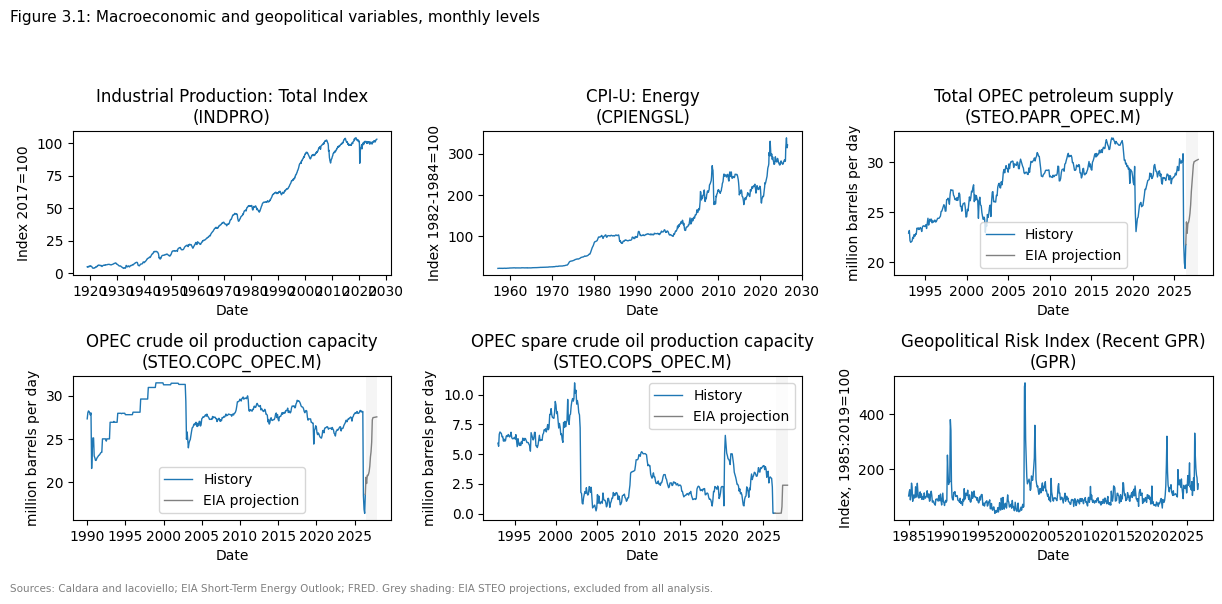

In [8]:
def plot_level(ax, k, s, mask=None):
    hist = s if mask is None else s.where(~mask)
    ax.plot(hist.index, hist.values, color="tab:blue", lw=1.0, label="History")
    if mask is not None and mask.any():
        proj = s.where(mask)
        last = hist.last_valid_index()
        proj.loc[last] = hist.loc[last]
        ax.plot(proj.index, proj.values, color="grey", lw=1.0, label="EIA projection")
        ax.axvspan(s.index[mask.values].min(), s.index.max(), color="whitesmoke", lw=0)
        ax.legend(loc="best")
    ax.set_title(f"{SHORT[k]}\n({k})")
    ax.set_ylabel(textwrap.fill(meta[k]["units"], 34))
    ax.set_xlabel("Date")
    span = (s.index.max() - s.index.min()).days
    ax.xaxis.set_major_locator(mdates.YearLocator(10 if span > 365 * 45 else 5))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

def level_grid(keys, title, ncols=3):
    nrows = int(np.ceil(len(keys) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.1 * ncols, 2.9 * nrows), squeeze=False)
    for ax, k in zip(axes.flat, keys):
        s = raw[k].dropna()
        if k in lowfreq_keys:
            plot_level(ax, k, s, pd.Series(s.index > meta[k]["last_historical"], index=s.index))
        elif k in monthly_raw:
            plot_level(ax, k, monthly_raw[k].dropna(), projection_mask[k][monthly_raw[k].notna()])
        else:
            plot_level(ax, k, s)
        if k == "^GSPC":
            ax.set_yscale("log")
            ax.set_ylabel("Index points (log scale)")
    for ax in axes.flat[len(keys):]:
        ax.set_visible(False)
    fig.suptitle(title, fontsize=11, x=0.01, ha="left")
    fig.tight_layout(rect=(0, 0, 1, 1 - 0.45 / fig.get_figheight()))
    srcs = sorted({meta[k]["source"].split(";")[0] for k in keys})
    note = "Sources: " + "; ".join(srcs) + "."
    if any(k.startswith("STEO") for k in keys):
        note += " Grey shading: EIA STEO projections, excluded from all analysis."
    caption(fig, note)
    plt.show()

macro_m = [k for k in monthly_keys if cat.loc[k, "category"] == "Macro/geopolitical"]
level_grid(macro_m, "Figure 3.1: Macroeconomic and geopolitical variables, monthly levels")

**Interpretation.** Figure 3.1 shows that the two U.S. indexes trend upward over decades, so their levels are not comparable over time and we analyse changes from Step 5 on. The three OPEC series move together and show an exceptional fall at the end of the sample: OPEC supply drops from about 31 to below 20 million barrels per day in early 2026, and spare capacity falls to almost zero (the exact values are reported in Step 5b). The GPR index is mostly between 50 and 150 with rare spikes, the largest in 2001, and a further spike in 2026. The data record these movements; our sources do not explain them, so we do not attribute a cause.

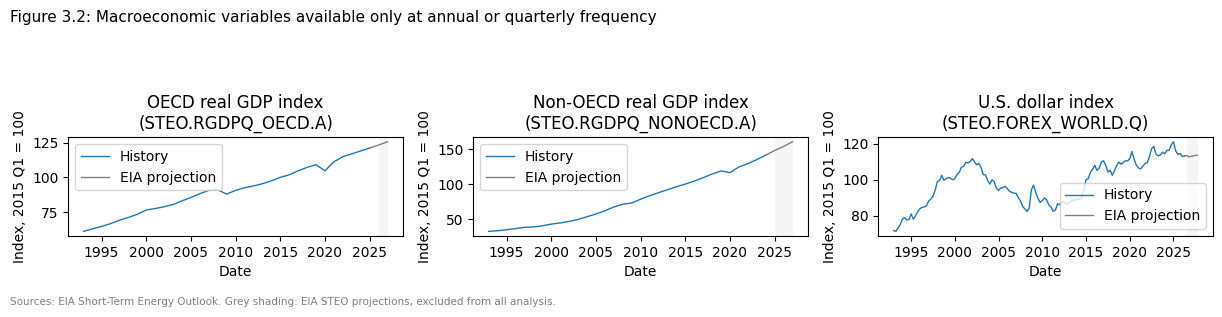

In [9]:
level_grid(lowfreq_keys, "Figure 3.2: Macroeconomic variables available only at annual or quarterly frequency")

**Interpretation.** Figure 3.2 shows the three series that Alvi used as monthly inputs but that EIA now publishes only annually (the GDP indexes) or quarterly (the dollar index), as Table 3.3 found. With about 30 annual observations, the GDP indexes cannot enter a monthly model without inventing most of the monthly values; we return to this in Step 5b.

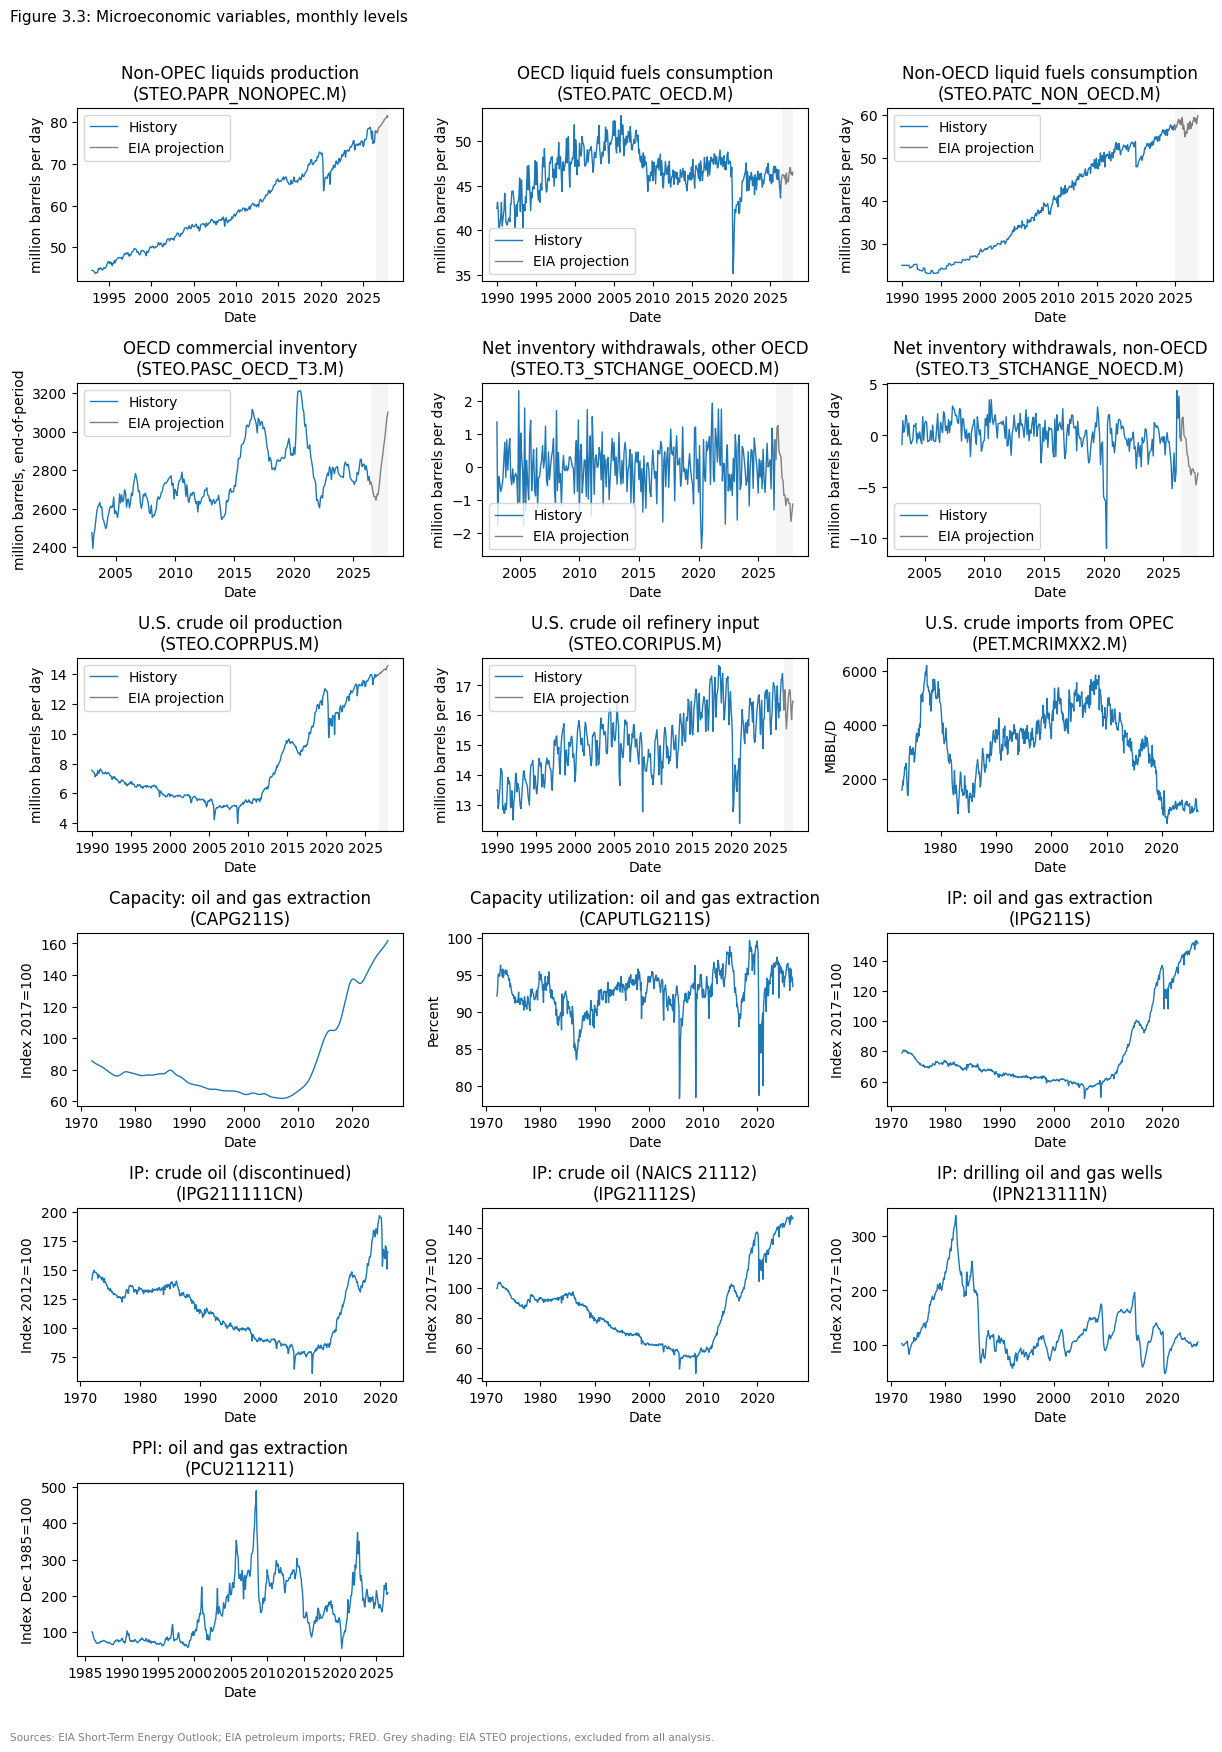

In [10]:
micro_m = [k for k in monthly_keys if cat.loc[k, "category"] == "Microeconomic"]
level_grid(micro_m, "Figure 3.3: Microeconomic variables, monthly levels")

**Interpretation.** Figure 3.3 shows strong trends in non-OPEC production, non-OECD consumption, U.S. crude production and the industrial production and capacity indexes, and clear seasonal swings in OECD consumption and U.S. refinery input. The inventory-withdrawal series move around zero, which is why we analyse them as first differences rather than log changes (Table 3.1). Almost every series shows a sharp break in 2020. The discontinued index `IPG211111CN` and its candidate replacement `IPG21112S` follow the same shape until 2021, on different base years (2012 and 2017), as Table 3.2 records.

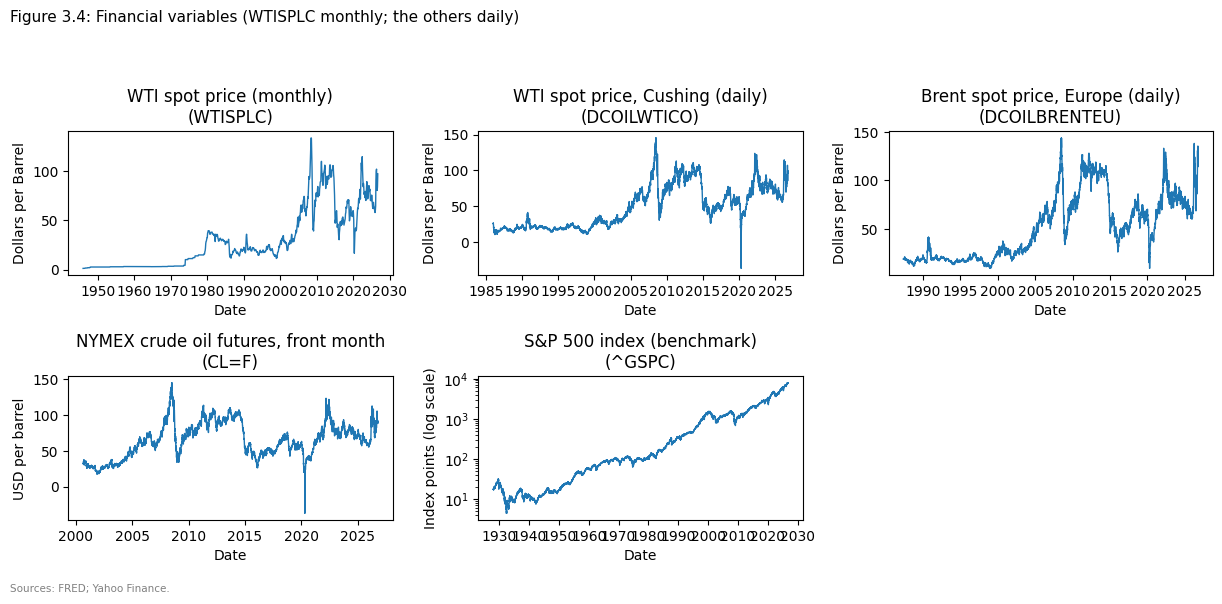

In [11]:
fin = ["WTISPLC"] + daily_keys
level_grid(fin, "Figure 3.4: Financial variables (WTISPLC monthly; the others daily)")

**Interpretation.** Figure 3.4 shows that the oil price moves in spikes and collapses rather than smooth trends, and that the daily WTI spot and futures prices both dip below zero in 2020, while Brent does not. The monthly WTI series is almost flat before the early 1970s, a period that Step 5 examines. The S&P 500, on a log scale, has a much steadier path, which already suggests the contrast that Step 8 tests.

## Step 4: Data dictionary and data table

We compiled the data dictionary from the metadata that each source returned at import (Tables 3.2 and 3.3). For each series it records the published name, ID, category, units, seasonal adjustment, frequency, source, the first and last historical observations, how far EIA projections run, the change we use in the analysis, and any breaks or notes. For STEO series the end of history is EIA's `lastHistoricalPeriod`, and "Not stated by source" means the source gives no seasonal adjustment.

**Table 4.1: Data dictionary**

| ID | Series (as published) | Category | Units | Seasonal adjustment | Frequency | Source | Start | End of history | EIA projections to | Change used | Breaks and notes |
|---|---|---|---|---|---|---|---|---|---|---|---|
| `INDPRO` | Industrial Production: Total Index | Macro/geopolitical | Index 2017=100 | Seasonally Adjusted | Monthly | FRED; Board of Governors of the Federal Reserve System (US) | Jan 1919 | Aug 2026 |  | Log difference |  |
| `CPIENGSL` | Consumer Price Index for All Urban Consumers: Energy in U.S. City Average | Macro/geopolitical | Index 1982-1984=100 | Seasonally Adjusted | Monthly | FRED; U.S. Bureau of Labor Statistics | Jan 1957 | Aug 2026 |  | Log difference |  |
| `STEO.PAPR_OPEC.M` | Total OPEC Petroleum Supply | Macro/geopolitical | million barrels per day | Not stated by source | Monthly | EIA Short-Term Energy Outlook | Jan 1993 | Jun 2026 | Dec 2027 | Log difference | B4: Angola's crude removed from OPEC crude production from Jan 2024. |
| `STEO.COPC_OPEC.M` | OPEC Total Crude Oil Production Capacity | Macro/geopolitical | million barrels per day | Not stated by source | Monthly | EIA Short-Term Energy Outlook | Jan 1990 | Jun 2026 | Dec 2027 | Log difference |  |
| `STEO.COPS_OPEC.M` | OPEC Total Spare Crude Oil Production Capacity | Macro/geopolitical | million barrels per day | Not stated by source | Monthly | EIA Short-Term Energy Outlook | Jan 1993 | Jun 2026 | Dec 2027 | First difference |  |
| `GPR` | Geopolitical Risk Index (Recent GPR) | Macro/geopolitical | Index, 1985:2019=100 | Not stated by source | Monthly | Caldara and Iacoviello | Jan 1985 | Sep 2026 |  | Log difference |  |
| `STEO.RGDPQ_OECD.A` | OECD Real Gross Domestic Product | Macro/geopolitical | Index, 2015 Q1 = 100 | Not stated by source | Annual | EIA Short-Term Energy Outlook | 1993 | 2025 | 2027 | Log difference | B2: PPP-weighted since Jan 2021; annual only. |
| `STEO.RGDPQ_NONOECD.A` | Non-OECD Real Gross Domestic Product | Macro/geopolitical | Index, 2015 Q1 = 100 | Not stated by source | Annual | EIA Short-Term Energy Outlook | 1993 | 2024 | 2027 | Log difference | B2: PPP-weighted since Jan 2021; annual only. |
| `STEO.FOREX_WORLD.Q` | Nominal U.S. Dollar Index, 2015 Q1=100 (annual and quarterly data only) | Macro/geopolitical | Index, 2015 Q1 = 100 | Not stated by source | Quarterly | EIA Short-Term Energy Outlook | 1993 Q1 | 2026 Q2 | 2027 Q4 | Log difference | B3: nominal trade-weighted since May 2021; quarterly and annual only; EIA description still describes the real index. |
| `STEO.PAPR_NONOPEC.M` | Total non-OPEC Liquids Petroleum Production | Microeconomic | million barrels per day | Not stated by source | Monthly | EIA Short-Term Energy Outlook | Jan 1993 | Jun 2026 | Dec 2027 | Log difference | B4: Angola's liquids added from Jan 2024. |
| `STEO.PATC_OECD.M` | Liquid Fuels Consumption, Total OECD | Microeconomic | million barrels per day | Not stated by source | Monthly | EIA Short-Term Energy Outlook | Jan 1990 | Jun 2026 | Dec 2027 | Log difference |  |
| `STEO.PATC_NON_OECD.M` | Liquid Fuels Consumption, Total non-OECD | Microeconomic | million barrels per day | Not stated by source | Monthly | EIA Short-Term Energy Outlook | Jan 1990 | Dec 2024 | Dec 2027 | Log difference |  |
| `STEO.PASC_OECD_T3.M` | OECD End-of-period Commercial Crude Oil and Other Liquids Inventory | Microeconomic | million barrels, end-of-period | Not stated by source | Monthly | EIA Short-Term Energy Outlook | Jan 2003 | Jun 2026 | Dec 2027 | Log difference |  |
| `STEO.T3_STCHANGE_OOECD.M` | Net Inventory Withdrawals, Total Other OECD Crude Oil and Other Liquids | Microeconomic | million barrels per day | Not stated by source | Monthly | EIA Short-Term Energy Outlook | Feb 2003 | Jun 2026 | Dec 2027 | First difference |  |
| `STEO.T3_STCHANGE_NOECD.M` | Net Inventory Withdrawals, Total Non-OECD Crude Oil and Other Liquids | Microeconomic | million barrels per day | Not stated by source | Monthly | EIA Short-Term Energy Outlook | Feb 2003 | Jun 2026 | Dec 2027 | First difference |  |
| `STEO.COPRPUS.M` | U.S. Crude Oil Production | Microeconomic | million barrels per day | Not stated by source | Monthly | EIA Short-Term Energy Outlook | Jan 1990 | Sep 2026 | Dec 2027 | Log difference |  |
| `STEO.CORIPUS.M` | Crude OIl Refinery Input | Microeconomic | million barrels per day | Not stated by source | Monthly | EIA Short-Term Energy Outlook | Jan 1990 | Sep 2026 | Dec 2027 | Log difference |  |
| `PET.MCRIMXX2.M` | U.S. Imports from OPEC Countries of Crude Oil (Thousand Barrels per Day) | Microeconomic | MBBL/D | Not stated by source | Monthly | EIA petroleum imports | Jan 1973 | Jul 2026 |  | Log difference |  |
| `CAPG211S` | Industrial Capacity: Mining: Oil and Gas Extraction (NAICS = 211) | Microeconomic | Index 2017=100 | Seasonally Adjusted | Monthly | FRED; Board of Governors of the Federal Reserve System (US) | Jan 1972 | Aug 2026 |  | Log difference |  |
| `CAPUTLG211S` | Capacity Utilization: Mining: Oil and Gas Extraction (NAICS = 211) | Microeconomic | Percent | Seasonally Adjusted | Monthly | FRED; Board of Governors of the Federal Reserve System (US) | Jan 1972 | Aug 2026 |  | First difference |  |
| `IPG211S` | Industrial Production: Mining: Oil and Gas Extraction (NAICS = 211) | Microeconomic | Index 2017=100 | Seasonally Adjusted | Monthly | FRED; Board of Governors of the Federal Reserve System (US) | Jan 1972 | Aug 2026 |  | Log difference |  |
| `IPG211111CN` | Industrial Production: Mining, Quarrying, and Oil and Gas Extraction: Crude Oil (NAICS = 211111pt.) (DISCONTINUED) | Microeconomic | Index 2012=100 | Not Seasonally Adjusted | Monthly | FRED; Board of Governors of the Federal Reserve System (US) | Jan 1972 | Apr 2021 |  | Log difference | B1: discontinued (ends Apr 2021); replaced by IPG21112S in the model panel (our judgement). |
| `IPG21112S` | Industrial Production: Mining: Crude Oil (NAICS = 21112) | Microeconomic | Index 2017=100 | Seasonally Adjusted | Monthly | FRED; Board of Governors of the Federal Reserve System (US) | Jan 1972 | Aug 2026 |  | Log difference | Our addition: candidate replacement for IPG211111CN (B1); NAICS 21112, 2017=100, SA. |
| `IPN213111N` | Industrial Production: Mining: Drilling Oil and Gas Wells (NAICS = 213111) | Microeconomic | Index 2017=100 | Not Seasonally Adjusted | Monthly | FRED; Board of Governors of the Federal Reserve System (US) | Jan 1972 | Aug 2026 |  | Log difference |  |
| `PCU211211` | Producer Price Index by Industry: Oil and Gas Extraction | Microeconomic | Index Dec 1985=100 | Not Seasonally Adjusted | Monthly | FRED; U.S. Bureau of Labor Statistics | Dec 1985 | Aug 2026 |  | Log difference |  |
| `WTISPLC` | Spot Crude Oil Price: West Texas Intermediate (WTI) | Financial | Dollars per Barrel | Not Seasonally Adjusted | Monthly | FRED; Federal Reserve Bank of St. Louis | Jan 1946 | Sep 2026 |  | Log difference | Spliced by FRED (OILPRICE to Jul 2013, MCOILWTICO after). Alvi's target. |
| `DCOILWTICO` | Crude Oil Prices: West Texas Intermediate (WTI) - Cushing, Oklahoma | Financial | Dollars per Barrel | Not Seasonally Adjusted | Daily | FRED; U.S. Energy Information Administration | 02 Jan 1986 | 06 Oct 2026 |  | Log difference |  |
| `DCOILBRENTEU` | Crude Oil Prices: Brent - Europe | Financial | Dollars per Barrel | Not Seasonally Adjusted | Daily | FRED; U.S. Energy Information Administration | 20 May 1987 | 06 Oct 2026 |  | Log difference |  |
| `CL=F` | Crude Oil Nov 26 (NY Mercantile) | Financial | USD per barrel | Not stated by source | Daily | Yahoo Finance | 23 Aug 2000 | 08 Oct 2026 |  | Log difference | Continuous front-month quote; roll dates not published. |
| `^GSPC` | S&P 500 (SNP) | Financial (benchmark) | Index points | Not stated by source | Daily | Yahoo Finance | 02 Jan 1986 | 08 Oct 2026 |  | Log difference | Benchmark only; used from Jan 1986. |
| `STEO.COPR_OPEC.M` | Crude Oil Production, OPEC Total | Diagnostic only | million barrels per day | Not stated by source | Monthly | EIA Short-Term Energy Outlook | Jan 1993 | Jun 2026 | Dec 2027 | Log difference |  |

**Interpretation.** Table 4.1 shows three features that shape the cleaning. First, coverage differs widely: monthly series start between 1919 (`INDPRO`) and 2003 (the OECD inventory and inventory-withdrawal series). Since Alvi merged his series with an inner join on dates (Alvi, 2018), the shortest series will set the common window. Second, STEO history ends at different months: most STEO series are historical to June or September 2026, but non-OECD consumption only to December 2024, and every later value is a projection. Third, seasonal adjustment is mixed. Six FRED series are seasonally adjusted and six are not, while the EIA, GPR and Yahoo sources do not state an adjustment, so the dictionary says "Not stated by source" rather than assuming one.

## Step 5: Clean the data

We first read Alvi's preprocessing. It has four steps: retrieval, cleaning, transformation and discretisation (Alvi, 2018). His cleaning converts the indexes to dates and replaces '-' placeholders in EIA data with missing values, which he then fills backwards from the next observation; he found that the FRED data needed no cleaning (Alvi, 2018). His transformation merges all series with an inner join on dates and splits them 80:10:10 into training, validation and test sets (Alvi, 2018).

We then applied three cleaning checks to every dataset: extreme outliers (5a), bad data (5b) and missing values (5c). For the outlier screen we used each series' historical values only; removing the EIA projections is itself a bad-data action, recorded in 5b. Step 6 records every action in a cleaning log.

In [12]:
def history(k):
    s = raw[k].copy()
    if "last_historical" in meta[k]:
        s = s[s.index <= meta[k]["last_historical"]]
    if cat.loc[k, "freq"] == "D":
        s = s.dropna()
        if k == "^GSPC":
            s = s[s.index >= "1986-01-01"]
    else:
        s = s.loc[s.first_valid_index():s.last_valid_index()]
    return s

def changes(s, transform):
    return np.log(s.where(s > 0)).diff() if transform == "logdiff" else s.diff()

def modified_z(x):
    x = x.dropna()
    med = x.median()
    mad = (x - med).abs().median()
    return 0.6745 * (x - med) / mad, mad

screen_keys = [k for k in cat.index if cat.loc[k, "category"] != "Diagnostic only"]

### Step 5a: Extreme outliers

We computed each series' period-on-period change, as a log difference for strictly positive levels and as a first difference for series that can be zero or negative (Table 4.1), and then the modified z-score $M_i = 0.6745\,(x_i - \tilde{x})/\mathrm{MAD}$, where $\tilde{x}$ is the median and MAD the median absolute deviation. Following Iglewicz and Hoaglin (as cited in NIST/SEMATECH, n.d.), we labelled changes with $|M_i| > 3.5$ as potential outliers (NIST/SEMATECH, n.d.). We screened changes rather than levels because trending levels look extreme simply for being recent, and we used the median and MAD because a few extreme values inflate the mean and standard deviation. NIST advises deleting an outlier only if it can be shown to be erroneous (NIST/SEMATECH, n.d.), so we labelled first and then looked for evidence of error.

In [13]:
flags, rows = {}, []
for k in screen_keys:
    z, mad = modified_z(changes(history(k), cat.loc[k, "transform"]))
    flags[k] = z[z.abs() > 3.5]
    rows.append({"ID": k, "changes": len(z), "MAD": round(mad, 5), "flagged": len(flags[k]),
                 "flagged %": round(100 * len(flags[k]) / len(z), 1), "largest |M|": round(z.abs().max(), 1),
                 "date of largest": z.abs().idxmax().date()})
z86, mad86 = modified_z(changes(history("WTISPLC")["1986-01-01":], "logdiff"))
f86 = z86[z86.abs() > 3.5]
rows.append({"ID": "WTISPLC (Jan 1986 on)", "changes": len(z86), "MAD": round(mad86, 5), "flagged": len(f86),
             "flagged %": round(100 * len(f86) / len(z86), 1), "largest |M|": round(z86.abs().max(), 1),
             "date of largest": z86.abs().idxmax().date()})
print("Table 5.1: Potential outliers, |modified z| > 3.5, by series")
pd.DataFrame(rows).set_index("ID")

Table 5.1: Potential outliers, |modified z| > 3.5, by series


,changes,MAD,flagged,flagged %,largest |M|,date of largest
ID,,,,,,
INDPRO,1291,0.00582,102,7.9,17.5,1933-05-01
CPIENGSL,833,0.00757,59,7.1,18.0,2008-11-01
STEO.PAPR_OPEC.M,401,0.00831,19,4.7,27.8,2026-03-01
STEO.COPC_OPEC.M,437,0.00365,34,7.8,77.9,2026-03-01
STEO.COPS_OPEC.M,401,0.19420,17,4.2,18.8,2003-01-01
GPR,500,0.12084,8,1.6,11.5,2001-09-01
STEO.RGDPQ_OECD.A,32,0.00673,3,9.4,6.7,2020-01-01
STEO.RGDPQ_NONOECD.A,31,0.00853,1,3.2,5.2,2020-01-01
STEO.FOREX_WORLD.Q,133,0.01539,1,0.8,4.7,2008-10-01


**Interpretation.** Table 5.1 shows that most series flag fewer than 5% of their changes. Six series flag more:

* `WTISPLC` flags 14.7% of its changes over 1946 to 2026 but only 2.0% when screened from January 1986, the period we analyse in Step 8. Its MAD is 0.0175 on the full history against 0.0538 from 1986, because the early history contains long spells of unchanged prices (Table 5.4 finds a run of 65 identical months from January 1948). The small full-sample MAD makes ordinary later moves look extreme, so the 1986 screen is the relevant one.
* `INDPRO` flags 7.9%, and its largest score falls in 1933, in an early period whose volatility is much larger than the full-sample MAD.
* `CAPG211S` is a very smooth capacity series with a tiny MAD, so small accelerations are flagged; its largest score is only 4.4.
* `CPIENGSL` (7.1%), `STEO.COPC_OPEC.M` (7.8%) and `STEO.RGDPQ_OECD.A` (9.4%, which is 3 of only 32 annual changes) have their largest scores in November 2008, March 2026 and 2020, episodes in which many series move together (Table 5.2, Figure 5.1).

In [14]:
monthly_screen = [k for k in screen_keys if cat.loc[k, "freq"] == "M"]
flag_m = pd.DataFrame({k: flags[k].reindex(monthly_raw.index).notna() for k in monthly_screen})
co = flag_m.sum(axis=1)
busy = co[co >= 3]
print(f"Monthly flags: {int(flag_m.values.sum())}; months with 3 or more series flagged: {len(busy)}, "
      f"holding {100 * flag_m.loc[busy.index].values.sum() / flag_m.values.sum():.0f}% of all monthly flags")
print("\nTable 5.2: Months with 5 or more series flagged")
print(pd.DataFrame({"series flagged": co[co >= 5]}).rename(index=lambda d: d.strftime("%Y-%m")).to_string())

wti_f = flags["DCOILWTICO"]
corrob = pd.Series(False, index=wti_f.index)
for other in ["DCOILBRENTEU", "CL=F"]:
    common = wti_f.index.intersection(flags[other].index)
    corrob[common] |= (np.sign(wti_f[common]) == np.sign(flags[other][common])).values
post = corrob[corrob.index >= raw["CL=F"].index.min()]
print(f"\nDaily WTI spot flags since Aug 2000: {len(post)}; matched with the same sign by Brent or CL=F on the same day: "
      f"{int(post.sum())} ({100 * post.mean():.0f}%)")

Monthly flags: 632; months with 3 or more series flagged: 49, holding 40% of all monthly flags

Table 5.2: Months with 5 or more series flagged
         series flagged
1998-09               6
2002-09               5
2002-11               5
2003-01               5
2005-09               7
2005-11               6
2008-09               9
2008-10              10
2008-11               8
2011-03               5
2015-01               5
2020-04              16
2020-05              13
2020-06              10
2020-07               7
2020-11               6
2021-02              10
2021-03               8
2021-10               5
2024-01               5
2026-03               8
2026-06               5

Daily WTI spot flags since Aug 2000: 157; matched with the same sign by Brent or CL=F on the same day: 118 (75%)


**Interpretation.** The flags are clustered in time rather than scattered. The output shows that 40% of all monthly flags fall in the 49 months in which three or more series are flagged together, and Table 5.2 shows that the largest clusters are April 2020 (16 series), May 2020, September to November 2008 and February 2021. On the daily side, since August 2000, when all three oil markets are available, 75% of flagged WTI spot moves are matched with the same sign by Brent or the futures price on the same day. A move that independent series and sources confirm is a market or economic event, not a recording error, so by NIST's rule (NIST/SEMATECH, n.d.) these values are kept.

In [15]:
uncorr = post.index[~post.values]
rs, rf, rb = (changes(history(k), "logdiff") for k in ["DCOILWTICO", "CL=F", "DCOILBRENTEU"])
spot_only = pd.DataFrame({"WTI spot": rs.reindex(uncorr), "WTI futures": rf.reindex(uncorr), "Brent spot": rb.reindex(uncorr)})
print(f"Table 5.3a: Largest WTI spot-only moves (flagged, not matched by Brent or futures), {len(uncorr)} in total")
print(spot_only.reindex(spot_only["WTI spot"].abs().sort_values(ascending=False).index).head(5).round(3).to_string())
print("\nTable 5.3b: Prices around 31 March 2020 (USD per barrel)")
pd.concat({k: history(k) for k in ["DCOILWTICO", "CL=F", "DCOILBRENTEU"]}, axis=1).loc["2020-03-25":"2020-04-02"].round(2)

Table 5.3a: Largest WTI spot-only moves (flagged, not matched by Brent or futures), 39 in total
            WTI spot  WTI futures  Brent spot
2020-03-31     0.375        0.019      -0.256
2003-03-19    -0.233       -0.058      -0.005
2020-03-23     0.180        0.041      -0.073
2026-09-28     0.153        0.002       0.034
2008-12-26     0.132        0.065      -0.021

Table 5.3b: Prices around 31 March 2020 (USD per barrel)


,DCOILWTICO,CL=F,DCOILBRENTEU
2020-03-25,20.75,24.49,25.62
2020-03-26,16.60,22.60,23.55
2020-03-27,15.48,21.51,22.39
2020-03-30,14.10,20.09,19.19
2020-03-31,20.51,20.48,14.85
2020-04-01,20.28,20.31,14.97
2020-04-02,25.18,25.32,20.24


**Interpretation.** The other 39 flagged WTI spot days are spot-only moves. Table 5.3a shows that the largest is 31 March 2020, a 37.5% spot log return on a day when the futures price rose 1.9% and Brent fell. Table 5.3b explains it: the spot price had been about \$3 to \$6 below the futures price for several days and then jumped back to it. The move therefore reflects how the daily spot assessment relates to the futures contract over the month, which our sources do not document. We keep these 39 values but label them questionable, and this is one reason Step 8 also reports the futures series.

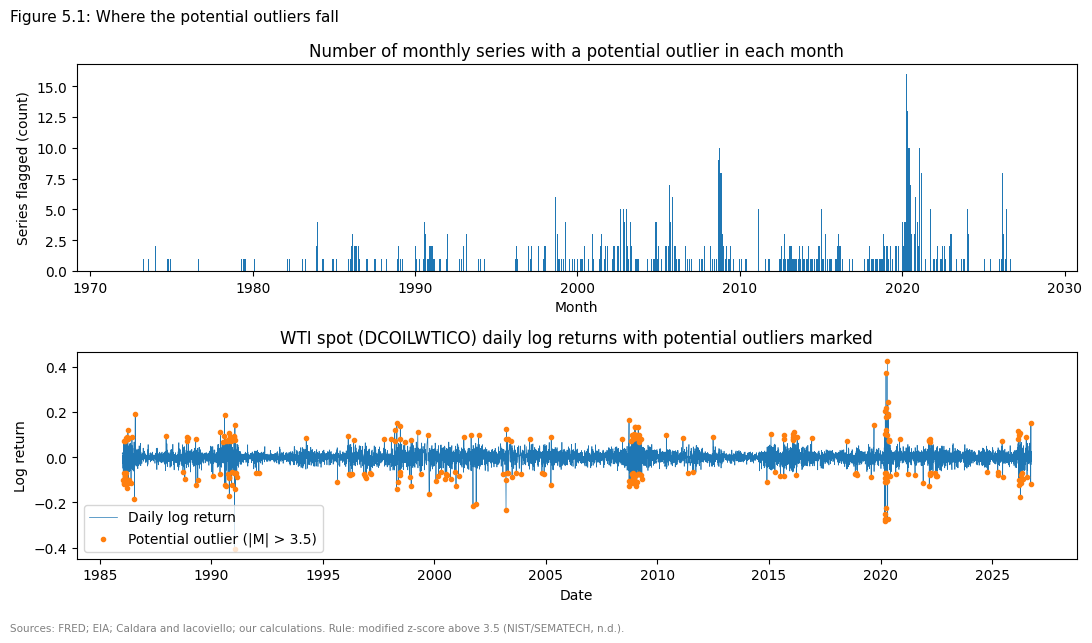

In [16]:
fig, axes = plt.subplots(2, 1, figsize=(11, 6.2))
cf = co[co.index >= "1972-01-01"]
axes[0].bar(cf.index, cf.values, width=25, color="tab:blue")
axes[0].set_title("Number of monthly series with a potential outlier in each month")
axes[0].set_ylabel("Series flagged (count)")
axes[0].set_xlabel("Month")
axes[1].plot(rs.index, rs.values, color="tab:blue", lw=0.5, label="Daily log return")
axes[1].scatter(wti_f.index, rs.reindex(wti_f.index), s=9, color="tab:orange", zorder=3, label="Potential outlier (|M| > 3.5)")
axes[1].set_title("WTI spot (DCOILWTICO) daily log returns with potential outliers marked")
axes[1].set_ylabel("Log return")
axes[1].set_xlabel("Date")
axes[1].legend(loc="lower left")
fig.suptitle("Figure 5.1: Where the potential outliers fall", x=0.01, ha="left", fontsize=11)
fig.tight_layout()
caption(fig, "Sources: FRED; EIA; Caldara and Iacoviello; our calculations. Rule: modified z-score above 3.5 (NIST/SEMATECH, n.d.).")
plt.show()

pd.DataFrame({k: flags[k] for k in screen_keys}).to_csv(CLEAN / "outlier_flags_modified_z.csv")

**Interpretation.** Figure 5.1 makes the clustering visible: the top panel has isolated spikes in late 2008 and a much larger one in 2020, and the bottom panel shows that flagged WTI returns bunch in the same episodes, above all March and April 2020. We therefore **retained every outlier** in the sterilised data and saved the scores to `outlier_flags_modified_z.csv`, so that later modelling can treat them with robust methods. The data points we do remove or exclude around extreme moves are removed for bad-data reasons in 5b, not for being large.

### Step 5b: Bad data

We checked every series for duplicate dates, non-numeric placeholders in the raw response, weekend dates in daily data, impossible values (zero or negative values in quantities that must be positive), non-positive prices before log returns, stale runs of identical values, and EIA projections. We then examined the definition changes B1 to B4, the splice inside `WTISPLC`, and, for the futures series, zero-volume days, inconsistent daily price ranges and contract rolls.

In [17]:
def max_run(s):
    s = s.dropna()
    sizes = s.groupby((s != s.shift()).cumsum()).transform("size")
    return int(sizes.max()), sizes.idxmax()

rows = []
for k in screen_keys:
    h = history(k)
    n_run, run_start = max_run(h)
    rows.append({"ID": k, "duplicate dates": raw[k].index.duplicated().sum(), "raw placeholders": meta[k]["placeholders"],
                 "weekend dates (daily only)": (raw[k].dropna().index.dayofweek >= 5).sum() if cat.loc[k, "freq"] == "D" else np.nan,
                 "non-positive": (h <= 0).sum(), "allowed negative": cat.loc[k, "allow_negative"],
                 "longest identical run": n_run, "run starts": run_start.date(),
                 "EIA projections": (raw[k].index > meta[k].get("last_historical", raw[k].index.max())).sum()})
print("Table 5.4: Bad-data checks by series")
pd.DataFrame(rows).set_index("ID")

Table 5.4: Bad-data checks by series


,duplicate dates,raw placeholders,weekend dates (daily only),non-positive,allowed negative,longest identical run,run starts,EIA projections
ID,,,,,,,,
INDPRO,0,0,NaN,0,False,3,1925-01-01,0
CPIENGSL,0,1,NaN,0,False,4,1966-02-01,0
STEO.PAPR_OPEC.M,0,0,NaN,0,False,1,1993-01-01,18
STEO.COPC_OPEC.M,0,0,NaN,0,False,12,1995-01-01,18
STEO.COPS_OPEC.M,0,0,NaN,0,False,3,2009-09-01,18
GPR,0,0,NaN,0,False,1,1985-01-01,0
STEO.RGDPQ_OECD.A,0,0,NaN,0,False,1,1993-01-01,2
STEO.RGDPQ_NONOECD.A,0,0,NaN,0,False,1,1993-01-01,3
STEO.FOREX_WORLD.Q,0,0,NaN,0,False,1,1993-01-01,6


**Interpretation.** Table 5.4 shows no duplicate dates in any series and no weekend dates in the daily series. Apart from the two inventory-withdrawal series, which are allowed to be negative, the only non-positive values are one WTI spot price and one futures close, examined below. The raw placeholders are FRED's "." entries for days or months without a value: one in `CPIENGSL` and over a thousand in each daily spot series, handled in 5c. The only long stale run is the 65 identical months of `WTISPLC` starting in January 1948, which lies outside the period we analyse. The last column counts the EIA projections, up to 18 months per STEO series and 36 for non-OECD consumption.

In [18]:
cu = history("CAPUTLG211S")
ident = (raw["STEO.COPC_OPEC.M"] - raw["STEO.COPR_OPEC.M"] - raw["STEO.COPS_OPEC.M"]).dropna()
print(f"Capacity utilization range: {cu.min():.2f} to {cu.max():.2f} percent")
print(f"Largest gap in spare capacity = capacity - crude production: {ident.abs().max():.1e} mb/d over {len(ident)} months")
opec = pd.concat({k: history(k) for k in ["STEO.PAPR_OPEC.M", "STEO.COPC_OPEC.M", "STEO.COPS_OPEC.M"]}, axis=1)
print("\nTable 5.5: OPEC series, last 12 historical months and full-sample minimum (million barrels per day)")
pd.concat([opec.tail(12).round(2).rename(index=lambda d: d.strftime("%Y-%m")),
           opec.min().round(2).to_frame("sample minimum").T, opec.idxmin().dt.strftime("%Y-%m").to_frame("month of minimum").T])

Capacity utilization range: 78.27 to 99.67 percent
Largest gap in spare capacity = capacity - crude production: 5.0e-09 mb/d over 420 months

Table 5.5: OPEC series, last 12 historical months and full-sample minimum (million barrels per day)


,STEO.PAPR_OPEC.M,STEO.COPC_OPEC.M,STEO.COPS_OPEC.M
2025-07,29.14,27.94,3.48
2025-08,29.16,27.99,3.56
2025-09,30.32,28.15,2.57
2025-10,30.07,28.29,3.0
2025-11,29.85,28.13,3.08
2025-12,30.1,28.22,3.0
2026-01,29.97,28.08,2.96
2026-02,30.82,28.16,2.22
2026-03,21.9,18.48,0.03
2026-04,19.95,16.91,0.01


**Interpretation.** Capacity utilization stays within 0 to 100 percent, and EIA's three OPEC series are internally consistent: spare capacity equals capacity minus crude production to within rounding error in all 420 months. Table 5.5 quantifies the 2026 movements seen in Figure 3.1: OPEC supply fell from 30.82 million barrels per day in February 2026 to 21.90 in March and reached its sample minimum of 19.38 in May, while spare capacity reached its sample minimum of 0.01 in April 2026. Because the series pass the identity check, we have no evidence that these values are errors, so we keep them.

**EIA projections.** We removed every STEO value after the series' last historical month, because projections are output of EIA's model, not observations.

In [19]:
projections = {k: raw[k].index[(raw[k].index > meta[k]["last_historical"]) & raw[k].notna()]
               for k in monthly_keys + lowfreq_keys if "last_historical" in meta[k]}
proj_table = pd.DataFrame({k: {"values removed": len(v), "first": v.min().date(), "last": v.max().date()} for k, v in projections.items()}).T
print(f"Table 5.6: EIA projections removed: {proj_table['values removed'].sum()} values in {len(proj_table)} series")
proj_table

Table 5.6: EIA projections removed: 221 values in 14 series


,values removed,first,last
STEO.PAPR_OPEC.M,18,2026-07-01,2027-12-01
STEO.COPC_OPEC.M,18,2026-07-01,2027-12-01
STEO.COPS_OPEC.M,18,2026-07-01,2027-12-01
STEO.PAPR_NONOPEC.M,18,2026-07-01,2027-12-01
STEO.PATC_OECD.M,18,2026-07-01,2027-12-01
STEO.PATC_NON_OECD.M,36,2025-01-01,2027-12-01
STEO.PASC_OECD_T3.M,18,2026-07-01,2027-12-01
STEO.T3_STCHANGE_OOECD.M,18,2026-07-01,2027-12-01
STEO.T3_STCHANGE_NOECD.M,18,2026-07-01,2027-12-01
STEO.COPRPUS.M,15,2026-10-01,2027-12-01


**Interpretation.** Table 5.6 shows that 221 projected values in 14 series were removed. This is the largest single cleaning action, and it matters most for non-OECD consumption, whose last 36 values are projections.

**Non-positive prices.** A log return is undefined at a non-positive price, so we checked whether an independent market recorded the same price on the same date.

In [20]:
price_keys = ["DCOILWTICO", "DCOILBRENTEU", "CL=F", "WTISPLC"]
neg = {k: history(k)[history(k) <= 0] for k in price_keys}
print("Table 5.7: Non-positive prices")
pd.DataFrame([(k, d.date(), round(x, 2)) for k, v in neg.items() for d, x in v.items()], columns=["series", "date", "price"])

Table 5.7: Non-positive prices


,series,date,price
0,DCOILWTICO,2020-04-20,-36.98
1,CL=F,2020-04-20,-37.63


**Interpretation.** Table 5.7 shows a WTI spot price of −36.98 dollars per barrel and a futures close of −37.63 on 20 April 2020; Brent and the monthly WTI series have no non-positive values. Two independent sources record a negative price on the same day, so we treat it as a genuine market price and keep it as a level. Only the two log returns that touch it are undefined, and we set them to missing rather than computing a return across the gap.

**Futures data quality and contract rolls.** Yahoo's continuous quote switches from the expiring contract to the next one without publishing the date. A switch appears as a jump in the futures price that the spot price does not share, so we computed the daily basis return (futures log return minus spot log return) and its modified z-score. If rolls drive the large basis moves, they should bunch in the part of the month when contracts switch.

CL=F zero-volume days: 13; days with open or close outside the high-low range: 7
Median daily rate of large basis moves: 7.2%; days of the month above twice that rate: [20, 21, 22, 23, 24, 25, 26, 27, 28]
Candidate roll days (at most one per month): 202 of 314 months


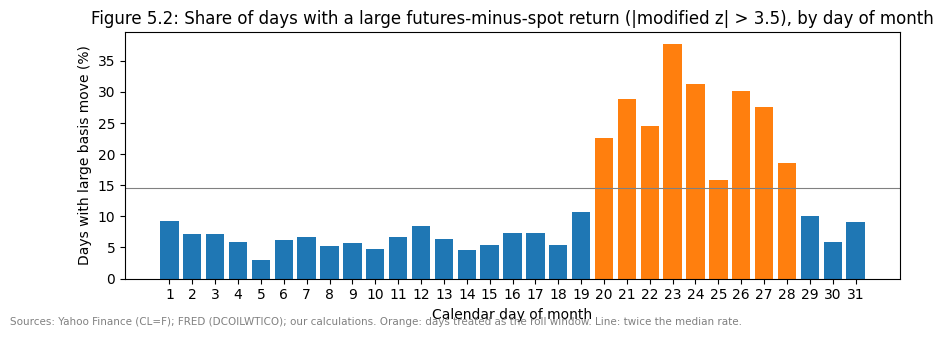

In [21]:
o = yahoo["CL=F"]["ohlcv"]
zero_vol = o.index[o["Volume"] == 0]
range_bad = o.index[(o["Close"] > o["High"] + 1e-9) | (o["Close"] < o["Low"] - 1e-9) | (o["Open"] > o["High"] + 1e-9) | (o["Open"] < o["Low"] - 1e-9)]
print(f"CL=F zero-volume days: {len(zero_vol)}; days with open or close outside the high-low range: {len(range_bad)}")

fut, spot = history("CL=F").drop(zero_vol, errors="ignore"), history("DCOILWTICO")
both = pd.concat([fut, spot], axis=1, join="inner")
basis = (changes(both["CL=F"], "logdiff") - changes(both["DCOILWTICO"], "logdiff")).dropna()
zb, _ = modified_z(basis)
big = zb.abs() > 3.5
by_day = pd.DataFrame({"days": zb.groupby(zb.index.day).size(), "large": big.groupby(zb.index.day).sum()})
by_day["rate %"] = 100 * by_day["large"] / by_day["days"]
base = by_day["rate %"].median()
roll_window = by_day.index[by_day["rate %"] > 2 * base].tolist()
in_win = zb[zb.index.day.isin(roll_window)]
best = in_win.abs().groupby(in_win.index.to_period("M")).idxmax()
roll_days = pd.DatetimeIndex([d for d in best if abs(zb[d]) > 3.5])
print(f"Median daily rate of large basis moves: {base:.1f}%; days of the month above twice that rate: {roll_window}")
print(f"Candidate roll days (at most one per month): {len(roll_days)} of {in_win.index.to_period('M').nunique()} months")

fig, ax = plt.subplots(figsize=(10, 3.2))
ax.bar(by_day.index, by_day["rate %"], color=["tab:orange" if d in roll_window else "tab:blue" for d in by_day.index], width=0.8)
ax.axhline(2 * base, color="grey", lw=0.8)
ax.set_title("Figure 5.2: Share of days with a large futures-minus-spot return (|modified z| > 3.5), by day of month")
ax.set_xlabel("Calendar day of month")
ax.set_ylabel("Days with large basis move (%)")
ax.set_xticks(range(1, 32))
caption(fig, "Sources: Yahoo Finance (CL=F); FRED (DCOILWTICO); our calculations. Orange: days treated as the roll window. Line: twice the median rate.")
plt.show()

**Interpretation.** Figure 5.2 shows that large futures-minus-spot moves occur on about 7% of days for most dates of the month but at more than twice that rate on days 20 to 28. This bunching is the pattern contract rolls would leave. Because a front-month series switches contract once a month, we treated at most one day per month as the roll, the day inside that window with the largest extreme basis move, and set its return to missing (202 of 314 months, per the output). We also removed the 13 zero-volume quotes and labelled the 7 days whose open or close lies outside the day's range. Yahoo does not publish its roll dates, so the exact roll rule remains an open question and our roll days are an approximation inferred from the data.

**Breaks B1 to B4 and the WTISPLC splice.** We cannot inspect EIA's earlier data vintages, so we asked a narrower question: does the current vintage show a jump at each break date that ordinary month-to-month variation would not produce?

In [22]:
breaks = pd.read_json(ROOT / "data" / "breaks.json")
breaks["date"] = pd.to_datetime(breaks["date"])

def monthly(k):
    s = history(k)
    return s.resample("MS").mean() if cat.loc[k, "freq"] == "D" else s

jumps = []
for _, b in breaks[breaks.check == "jump"].iterrows():
    ch = changes(history(b.series), cat.loc[b.series, "transform"])
    jumps.append({"break": b["break"], "series": b.series, "date": b.date.date(), "change": ch[b.date], "modified z": modified_z(ch)[0][b.date]})

overlaps = []
for _, b in breaks[breaks.check == "overlap"].iterrows():
    x, y = monthly(b.series), monthly(b.compare_with)
    both = pd.concat([x, y], axis=1).dropna()
    gap = (both.iloc[:, 0] - both.iloc[:, 1]).abs()
    overlaps.append({"break": b["break"], "series": b.series, "compared with": b.compare_with, "months": len(both),
                     "corr, monthly log changes": np.log(both).diff().corr().iloc[0, 1],
                     "corr, 12-month log changes": np.log(both).diff(12).corr().iloc[0, 1],
                     "mean |gap| before date": gap[:b.date - pd.DateOffset(days=1)].mean() if b.compare_levels else np.nan,
                     "mean |gap| from date": gap[b.date:].mean() if b.compare_levels else np.nan})

print("Table 5.8a: Change at each documented break date (change as used in the analysis, Table 4.1)")
display(pd.DataFrame(jumps).round(4))
print("Table 5.8b: Overlap comparisons")
pd.DataFrame(overlaps).round(4)

Table 5.8a: Change at each documented break date (change as used in the analysis, Table 4.1)


,break,series,date,change,modified z
0,B3,STEO.FOREX_WORLD.Q,2021-04-01,-0.0042,-0.4526
1,B4,STEO.COPR_OPEC.M,2024-01-01,-0.0068,-0.5850
2,B4,STEO.PAPR_OPEC.M,2024-01-01,-0.0075,-0.6939
3,B4,STEO.PAPR_NONOPEC.M,2024-01-01,-0.0300,-4.2606
4,B4 (control),STEO.COPRPUS.M,2024-01-01,-0.0599,-4.2626
5,Splice,WTISPLC,2013-08-01,0.0186,0.7162


Table 5.8b: Overlap comparisons


,break,series,compared with,months,"corr, monthly log changes","corr, 12-month log changes",mean |gap| before date,mean |gap| from date
0,B1,IPG211111CN,IPG21112S,592,0.9531,0.9977,NaN,NaN
1,Splice,WTISPLC,DCOILWTICO,489,0.9983,0.9999,0.0952,0.0122


**Interpretation.** Tables 5.8a and 5.8b support four decisions.

* **B1.** The discontinued crude oil index and its candidate replacement have 12-month log changes correlated at 0.998 over their 592 overlapping months (Table 5.8b), so we used `IPG21112S` in the model panel. Keeping `IPG211111CN` would end the common window in April 2021 (Table 3.2).
* **B2 and B3.** The GDP and dollar indexes are no longer monthly (Table 3.3), so we kept them at their native frequency rather than invent two of every three (quarterly) or eleven of every twelve (annual) monthly values. The dollar index shows no jump in the quarter of the 2021 change (modified z of −0.45, Table 5.8a), which is consistent with EIA restating its history on the new basis, but we cannot confirm this. EIA's name for the series says "Nominal U.S. Dollar Index", while the description in the bulk file still describes a weighted geometric mean of *real* exchange rates with oil-consumption weights (Table 4.1), so the definition of its history is an open question.
* **B4.** EIA's notice says Angola's crude was removed from OPEC crude production and Angola's total liquids added to non-OPEC supply from January 2024 (EIA, n.d.-b). Table 5.8a shows that OPEC crude production barely moved that month (modified z −0.59), so the current vintage shows no step. Non-OPEC supply fell sharply (modified z −4.26), but U.S. crude production, which the Angola change does not touch, fell just as sharply in the same month (modified z −4.26), and adding Angola would have raised non-OPEC supply, not lowered it. We kept the values and labelled the date.
* **Splice.** Table 5.8b shows that `WTISPLC` matches the monthly mean of daily WTI prices to within about one cent on average from August 2013 (mean absolute gap 0.012 dollars, against 0.095 before), and Table 5.8a shows no jump at the splice (modified z +0.72). This also tells us that the monthly target is an average of daily prices, which matters in Step 8.

### Step 5c: Missing values

Missing values arise in three places: a gap inside a monthly series' history, dates that FRED lists without a daily price, and months outside a series' coverage. We handled each differently and counted the imputed points per series.

In [23]:
gaps = {k: history(k).index[history(k).isna()] for k in screen_keys if cat.loc[k, "freq"] == "M" and history(k).isna().any()}

def impute_monthly(s):
    return s.interpolate(method="time", limit_area="inside")

for k, idx in gaps.items():
    filled = impute_monthly(history(k))
    print(f"Table 5.9: {k} around the gap (imputed value in {idx[0]:%b %Y})")
    print(filled.loc[idx[0] - pd.DateOffset(months=2):idx[0] + pd.DateOffset(months=2)].round(3).to_string())

Table 5.9: CPIENGSL around the gap (imputed value in Oct 2025)
2025-08-01    276.734
2025-09-01    280.700
2025-10-01    282.642
2025-11-01    284.648
2025-12-01    285.624


**Interpretation.** Table 5.9 shows that the only interior gap in the monthly data is October 2025 in `CPIENGSL`, filled by linear interpolation between September (280.700) and November (284.648), which gives 282.642. We did not follow Alvi's backward fill (Alvi, 2018): it copies the following month's value, which uses future information and creates a zero change that Alvi's up/down coding would read as a fall (Alvi, 2018).

In [24]:
daily_missing, by_year = {}, {}
for k in ["DCOILWTICO", "DCOILBRENTEU"]:
    s = raw[k][raw[k].index >= raw[k].first_valid_index()]
    daily_missing[k] = s.index[s.isna()]
    era = daily_missing[k][daily_missing[k] >= fut.index.min()]
    traded = pd.Series(era.isin(fut.index), index=era)
    by_year[(k, "futures closed")] = (~traded).groupby(era.year).sum()
    by_year[(k, "futures traded")] = traded.groupby(era.year).sum()
fut_r = changes(fut, "logdiff")
fut_r[fut_r.index.isin(roll_days)] = np.nan
sf = pd.concat([changes(spot, "logdiff"), fut_r], axis=1, join="inner").dropna()
print({k: len(v) for k, v in daily_missing.items()}, "dates without a price in total")
print(f"Correlation of daily WTI spot and CL=F log returns, roll days excluded: {sf.corr().iloc[0, 1]:.3f} over {len(sf)} days")
print("Table 5.10: Dates without a spot price since Aug 2000, by year and by whether NYMEX futures traded that day")
pd.DataFrame(by_year).fillna(0).astype(int)

{'DCOILWTICO': 1117, 'DCOILBRENTEU': 1173} dates without a price in total
Correlation of daily WTI spot and CL=F log returns, roll days excluded: 0.929 over 5964 days
Table 5.10: Dates without a spot price since Aug 2000, by year and by whether NYMEX futures traded that day


DCOILWTICO                  DCOILBRENTEU               
     futures closed futures traded futures closed futures traded
2000              4             12              2             22
2001             11             22              9             58
2002             11             21              4             63
2003             11            111              4             41
2004             13             64              3             29
2005              9             47              1             35
2006             10             24              3             28
2007              9              4              9              5
2008              9              0              9              0
2009              9              2              9              0
2010              9              0              9              0
2011              8             40              8              4
2012              9              0              9              3
2013              9              2              9              0
2014              9              4              7              1
2015              9              8              5              1
2016              9              0              5              1
2017              9              1              3              1
2018              9              3              4              5
2019              9              2              4              0
2020              9              1              4              3
2021              9              1              3              5
2022              9              0              2              6
2023             10              2              4              5
2024             10              2              4              4
2025             10              3              4              4
2026              8              0              3              3

**Interpretation.** The output shows 1,117 WTI and 1,173 Brent dates without a price, and Table 5.10 shows that they are of two kinds. Since August 2000, 8 to 13 WTI gaps a year (in full years) fall on days when the futures market was also closed; these are market holidays. The rest cluster in particular years, led by 2003, 2004 and 2005, on days when futures traded normally; these are genuinely missing spot assessments. In each series' own daily file we dropped the empty dates, so the next return spans the gap and nothing is invented.

For the cross-market analysis in Step 7c the series must share one calendar, so we built an aligned panel on every date when at least one oil market has a price. There we filled a missing WTI spot price on a futures trading day (not a roll day) by moving the previous spot price by that day's futures return, $\hat{P}^{spot}_t = P^{spot}_{t-1} \times F_t / F_{t-1}$, which the 0.929 correlation between daily spot and futures returns supports. Other gaps, such as London holidays for Brent, are filled by carrying the last price forward for at most three days, which gives a zero return as for a closed market. Months outside a series' coverage are not imputed; the inner join in Step 6 handles them, as in Alvi's method (Alvi, 2018).

In [25]:
def aligned_daily(hist_d, roll_days, limit=3):
    oil = ["DCOILWTICO", "DCOILBRENTEU", "CL=F"]
    cal = hist_d[oil[0]].index.union(hist_d[oil[1]].index).union(hist_d[oil[2]].index)
    cal = cal[cal >= hist_d["DCOILWTICO"].index.min()]
    fpx = hist_d["CL=F"].reindex(cal)
    out, imputed = {}, {}
    for k, s in hist_d.items():
        r = s.reindex(cal)
        r = r[r.index >= s.index.min()].copy()
        imputed[k] = {"futures-implied": [], "carried forward": []}
        if k == "DCOILWTICO":
            for i in range(1, len(r)):
                d, d0 = r.index[i], r.index[i - 1]
                if np.isnan(r.iat[i]) and r.iat[i - 1] > 0 and d not in roll_days \
                        and fpx.get(d, np.nan) > 0 and fpx.get(d0, np.nan) > 0:
                    r.iat[i] = r.iat[i - 1] * fpx[d] / fpx[d0]
                    imputed[k]["futures-implied"].append(d)
        before = r.isna()
        r = r.ffill(limit=limit)
        imputed[k]["carried forward"] = list(r.index[before & r.notna()])
        out[k] = r
    return pd.DataFrame(out), imputed

## Step 6: The sterilised dataset

We combined the decisions of Step 5 into one pipeline that runs in a fixed order (bad data, then missing values; outliers are labelled, not removed) and writes the sterilised files to `data/clean/`: every monthly series with history only (`monthly_clean.csv`), Alvi's inner-join panel of the model variables (`monthly_model_panel.csv`), the annual and quarterly series (`low_frequency.csv`), the daily prices on their own trading days (`daily_prices.csv`), the aligned daily panel (`daily_aligned_prices.csv`) and daily log returns with undefined and roll-day returns removed (`daily_log_returns.csv`). The cleaning log follows the output.

In [26]:
MODEL_EXCLUDE = {"IPG211111CN"}

def sterilize():
    out = {}
    hist = {k: history(k) for k in screen_keys}
    hist["CL=F"] = hist["CL=F"].drop(zero_vol, errors="ignore")
    for k in gaps:
        hist[k] = impute_monthly(hist[k])
    out["monthly_clean"] = pd.concat([hist[k] for k in monthly_keys], axis=1).rename_axis("month")
    model_keys = [k for k in monthly_keys if k not in MODEL_EXCLUDE]
    starts = {k: hist[k].first_valid_index() for k in model_keys}
    ends = {k: hist[k].last_valid_index() for k in model_keys}
    w0, w1 = max(starts.values()), min(ends.values())
    out["monthly_model_panel"] = out["monthly_clean"].loc[w0:w1, model_keys]
    out["window"] = (w0, w1, [k for k, v in starts.items() if v == w0], [k for k, v in ends.items() if v == w1])
    out["low_frequency"] = pd.concat([hist[k] for k in lowfreq_keys], axis=1).rename_axis("period_start")
    out["daily_prices"] = pd.concat([hist[k] for k in daily_keys], axis=1).rename_axis("date")
    rets = {k: changes(hist[k], "logdiff") for k in daily_keys}
    rets["CL=F"][rets["CL=F"].index.isin(roll_days)] = np.nan
    out["daily_log_returns"] = pd.concat(rets, axis=1).rename_axis("date")
    out["daily_aligned_prices"], out["aligned_imputed"] = aligned_daily({k: hist[k] for k in daily_keys}, roll_days)
    return out

S = sterilize()
for name in ["monthly_clean", "monthly_model_panel", "low_frequency", "daily_prices", "daily_aligned_prices", "daily_log_returns"]:
    S[name].to_csv(CLEAN / f"{name}.csv")

w0, w1, start_bind, end_bind = S["window"]
Mp = S["monthly_model_panel"]
n = len(Mp)
i80, i90 = int(n * 0.8), int(n * 0.9)
print(f"Common window: {w0:%b %Y} to {w1:%b %Y} ({n} months); start set by {start_bind}; end set by {end_bind}")
print(f"Missing values in the model panel: {int(Mp.isna().sum().sum())}")
print(f"Alvi's 80:10:10 split: train {Mp.index[0]:%b %Y}-{Mp.index[i80 - 1]:%b %Y} ({i80}), validation {Mp.index[i80]:%b %Y}-{Mp.index[i90 - 1]:%b %Y} ({i90 - i80}), "
      f"test {Mp.index[i90]:%b %Y}-{Mp.index[-1]:%b %Y} ({n - i90})")
A = S["daily_aligned_prices"]
print("\nTable 6.1: Imputed prices in the aligned daily panel")
pd.DataFrame({k: {m: len(v) for m, v in d.items()} for k, d in S["aligned_imputed"].items()}).T.assign(
    **{"still missing": {k: int(A[k].loc[A[k].first_valid_index():].isna().sum()) for k in A}})

Common window: Feb 2003 to Dec 2024 (263 months); start set by ['STEO.T3_STCHANGE_OOECD.M', 'STEO.T3_STCHANGE_NOECD.M']; end set by ['STEO.PATC_NON_OECD.M']
Missing values in the model panel: 0
Alvi's 80:10:10 split: train Feb 2003-Jul 2020 (210), validation Aug 2020-Sep 2022 (26), test Oct 2022-Dec 2024 (27)

Table 6.1: Imputed prices in the aligned daily panel


,futures-implied,carried forward,still missing
DCOILWTICO,362,387,10
DCOILBRENTEU,0,803,55
CL=F,0,133,2
^GSPC,0,164,1


**Interpretation.** The output shows that the common window runs from **February 2003 to December 2024 (263 months)**, set at the start by the two inventory-withdrawal series and at the end by non-OECD consumption, with no missing values inside it. Applying Alvi's 80:10:10 split (Alvi, 2018) gives 210 training, 26 validation and 27 test months. Table 6.1 shows that the aligned daily panel needed 362 futures-implied WTI prices and between 133 and 803 carried-forward prices per series.

**Cleaning log.** Every action we took in Step 5, with the number of data points affected and the table or figure that supports it.

| Step | Series | Points | Action | Reason | Evidence |
|---|---|---|---|---|---|
| 5a | 29 series | 1,604 | Labelled as potential outliers; kept | Modified z-score above 3.5; corroborated across series and sources | Tables 5.1, 5.2; Figure 5.1 |
| 5a | `DCOILWTICO` | 39 | Kept; labelled questionable | Spot-only moves, not matched by Brent or futures on the same day | Tables 5.3a, 5.3b |
| 5b | 14 STEO series | 221 | Removed | EIA projections after the last historical month | Table 5.6 |
| 5b | `DCOILWTICO`, `CL=F` | 1 each | Level kept; excluded from returns | Negative price on 20 April 2020, confirmed by spot and futures | Table 5.7 |
| 5b | `DCOILWTICO`, `CL=F` | 2 each | Return set to missing | Log returns into and out of a non-positive price are undefined | Table 5.7 |
| 5b | `CL=F` | 13 | Removed | Zero reported volume | Step 5b output |
| 5b | `CL=F` | 7 | Kept; labelled questionable | Open or close outside the day's high-low range | Step 5b output |
| 5b | `CL=F` | 202 | Return set to missing | Candidate contract roll days | Figure 5.2 |
| 5b | `^GSPC` | All rows before 1986 | Removed | Outside the benchmark window, which starts in January 1986 | Table 8.1 |
| 5b | `IPG211111CN` | Whole series | Excluded from model panel | B1: discontinued; replaced by `IPG21112S` | Table 5.8b |
| 5b | `RGDPQ_OECD`, `RGDPQ_NONOECD`, `FOREX_WORLD` | Whole series | Kept at native frequency | B2, B3: no longer published monthly | Table 3.3 |
| 5b | `STEO.PAPR_NONOPEC.M` | 1 | Kept; labelled | B4 date, January 2024 | Table 5.8a |
| 5b | `WTISPLC` | 65 | Kept; outside analysis window | Stale run of identical prices from January 1948 | Table 5.4 |
| 5c | `CPIENGSL` | 1 | Imputed by linear interpolation | Single interior gap, October 2025 | Table 5.9 |
| 5c | `DCOILWTICO`, `DCOILBRENTEU` | 1,117 and 1,173 | Dropped from own daily file | No price published on those dates | Table 5.10 |
| 5c | `DCOILWTICO` | 362 | Imputed in aligned panel (futures-implied price) | Spot price missing on a futures trading day | Table 6.1 |
| 5c | Four daily series | 387, 803, 133, 164 | Imputed in aligned panel (last price carried forward) | No price on the aligned calendar, at most 3 days | Table 6.1 |

**Why each data point, event or period was eliminated or adjusted:**

* **EIA projections** were eliminated because they are EIA's forecasts, not observations (Table 5.6); a model trained on them would learn EIA's model rather than the market.
* **Months outside the common window** were eliminated from the model panel because Alvi's method needs every variable observed in every month (Alvi, 2018). The discontinued `IPG211111CN` was replaced, because keeping it would end the window in April 2021 (Table 3.2) instead of December 2024 (Step 6 output) and lose 44 months.
* **The annual GDP indexes and the quarterly dollar index** were kept separate, because EIA no longer publishes them monthly (Table 3.3) and interpolation would invent most of the values.
* **The negative WTI price** was kept as a level and excluded from returns, because a log return through it is undefined and the price is confirmed by the futures market.
* **Futures roll days and zero-volume quotes** were excluded (Figure 5.2), because a roll-day return mixes two contracts and a zero-volume quote cannot be confirmed as a trade.
* **The S&P 500 before 1986** was eliminated, because it serves only as a benchmark for the oil period.
* **Daily dates without a price** were dropped from each series' own file and imputed only in the aligned panel (Table 5.10, Table 6.1), and **the single missing CPI month** was interpolated (Table 5.9).
* **Extreme values** were kept, because they are corroborated across series and sources (Table 5.2, Figure 5.1).

## Step 7: Exploratory data analysis

We explored all datasets with three kinds of plots: distributional plots (histograms with a fitted normal, and QQ plots), time-series plots (changes and rolling volatility) and multivariate plots (correlation heatmap, rolling correlations, a scatter matrix and cross-market correlations). Monthly series are analysed as changes over the common window, February 2003 to December 2024, so that every series covers the same months; `IPG211111CN` is shown over its part of the window and the annual and quarterly series over their own history. Daily series are analysed as log returns on their own trading days.

In [27]:
MC = S["monthly_clean"]
w0, w1 = S["window"][0], S["window"][1]
chg_m = {k: changes(MC[k].loc[w0:w1].dropna(), cat.loc[k, "transform"]).dropna() for k in monthly_keys}
chg_low = {k: changes(S["low_frequency"][k].dropna(), "logdiff").dropna() for k in lowfreq_keys}
R = S["daily_log_returns"]
rd = {k: R[k].dropna() for k in daily_keys}
P = S["daily_prices"]
D_LABEL = {"DCOILWTICO": "WTI spot", "DCOILBRENTEU": "Brent spot", "CL=F": "WTI futures", "^GSPC": "S&P 500 (benchmark)"}
NOTE_M = (f"Monthly changes, {w0:%b %Y} to {w1:%b %Y}; annual and quarterly series over their own history. "
          "Sources: FRED; EIA; Caldara and Iacoviello; our calculations.")

def chg_label(k):
    return "Log change" if cat.loc[k, "transform"] == "logdiff" else f"Change ({textwrap.shorten(meta[k]['units'], 26)})"

def grid(n, ncols=4, w=3.3, h=2.5):
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(w * ncols, h * nrows), squeeze=False)
    for ax in axes.flat[n:]:
        ax.set_visible(False)
    return fig, axes.flat

def finish(fig, title, note):
    fig.suptitle(title, fontsize=11, x=0.01, ha="left")
    fig.tight_layout(rect=(0, 0, 1, 1 - 0.45 / fig.get_figheight()))
    caption(fig, note)
    plt.show()

def year_axis(ax, step=5):
    ax.xaxis.set_major_locator(mdates.YearLocator(step))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

### Step 7a: Distributional plots

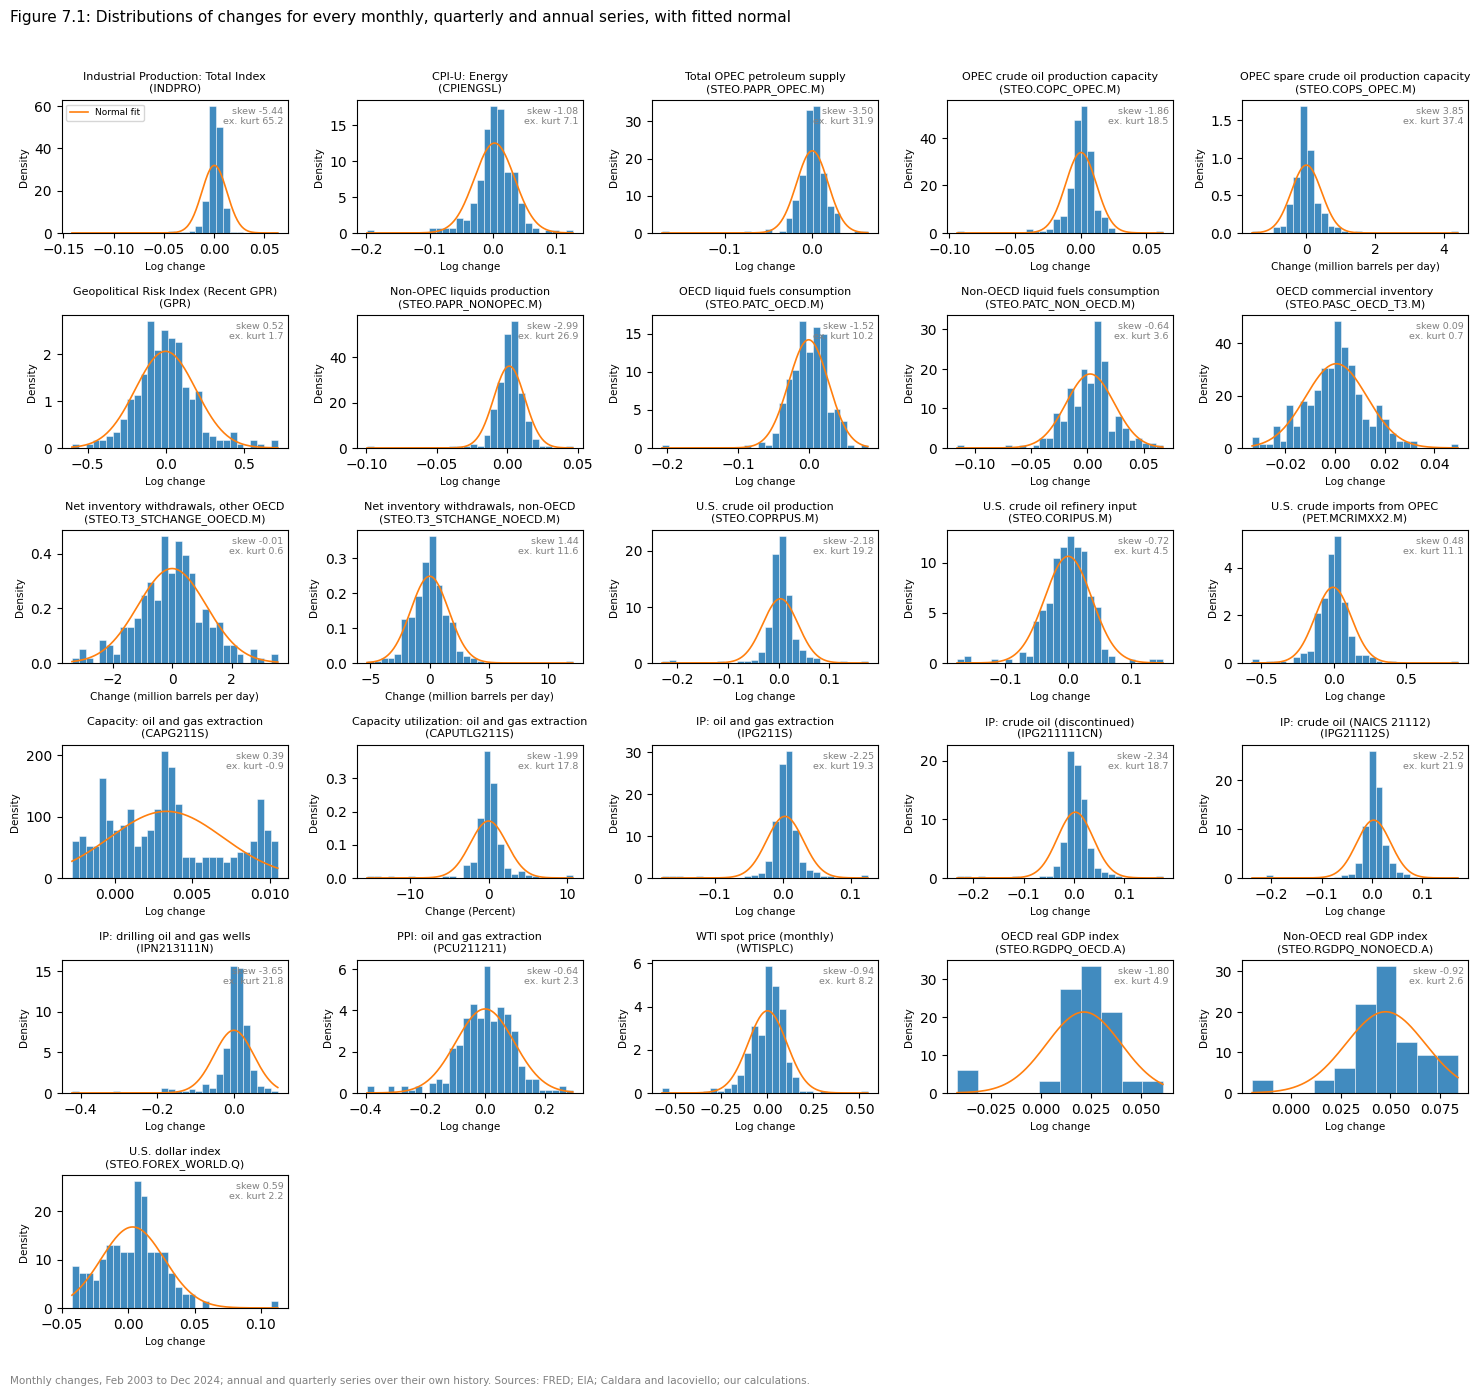

Series with excess kurtosis above 3: 19 of 26; median excess kurtosis 10.7


In [28]:
dist_keys = monthly_keys + lowfreq_keys
fig, axs = grid(len(dist_keys), ncols=5, w=3.0, h=2.3)
for ax, k in zip(axs, dist_keys):
    x = chg_m.get(k, chg_low.get(k))
    ax.hist(x, bins=30 if len(x) > 60 else 10, density=True, color="tab:blue", alpha=0.85, edgecolor="white", linewidth=0.4)
    g = np.linspace(x.min(), x.max(), 200)
    ax.plot(g, stats.norm.pdf(g, x.mean(), x.std()), color="tab:orange", lw=1.2, label="Normal fit")
    ax.set_title(f"{SHORT[k]}\n({k})", fontsize=8)
    ax.set_xlabel(chg_label(k), fontsize=7.5)
    ax.set_ylabel("Density", fontsize=7.5)
    ax.text(0.98, 0.95, f"skew {stats.skew(x):.2f}\nex. kurt {stats.kurtosis(x):.1f}", transform=ax.transAxes, ha="right", va="top", fontsize=6.8, color="grey")
axs[0].legend(loc="upper left", fontsize=6.5)
finish(fig, "Figure 7.1: Distributions of changes for every monthly, quarterly and annual series, with fitted normal", NOTE_M)
sk = pd.DataFrame({k: {"skewness": stats.skew(chg_m.get(k, chg_low.get(k))), "excess kurtosis": stats.kurtosis(chg_m.get(k, chg_low.get(k)))} for k in dist_keys}).T
print(f"Series with excess kurtosis above 3: {int((sk['excess kurtosis'] > 3).sum())} of {len(sk)}; median excess kurtosis {sk['excess kurtosis'].median():.1f}")

**Interpretation.** Figure 7.1 shows that most series are more peaked than the fitted normal and have longer tails. The output quantifies this: 19 of the 26 series have excess kurtosis above 3, and the median is 10.7, while a normal distribution has excess kurtosis 0. For the two annual GDP indexes, with only 31 and 32 changes, these shape statistics rest on very few observations and should be read with caution.

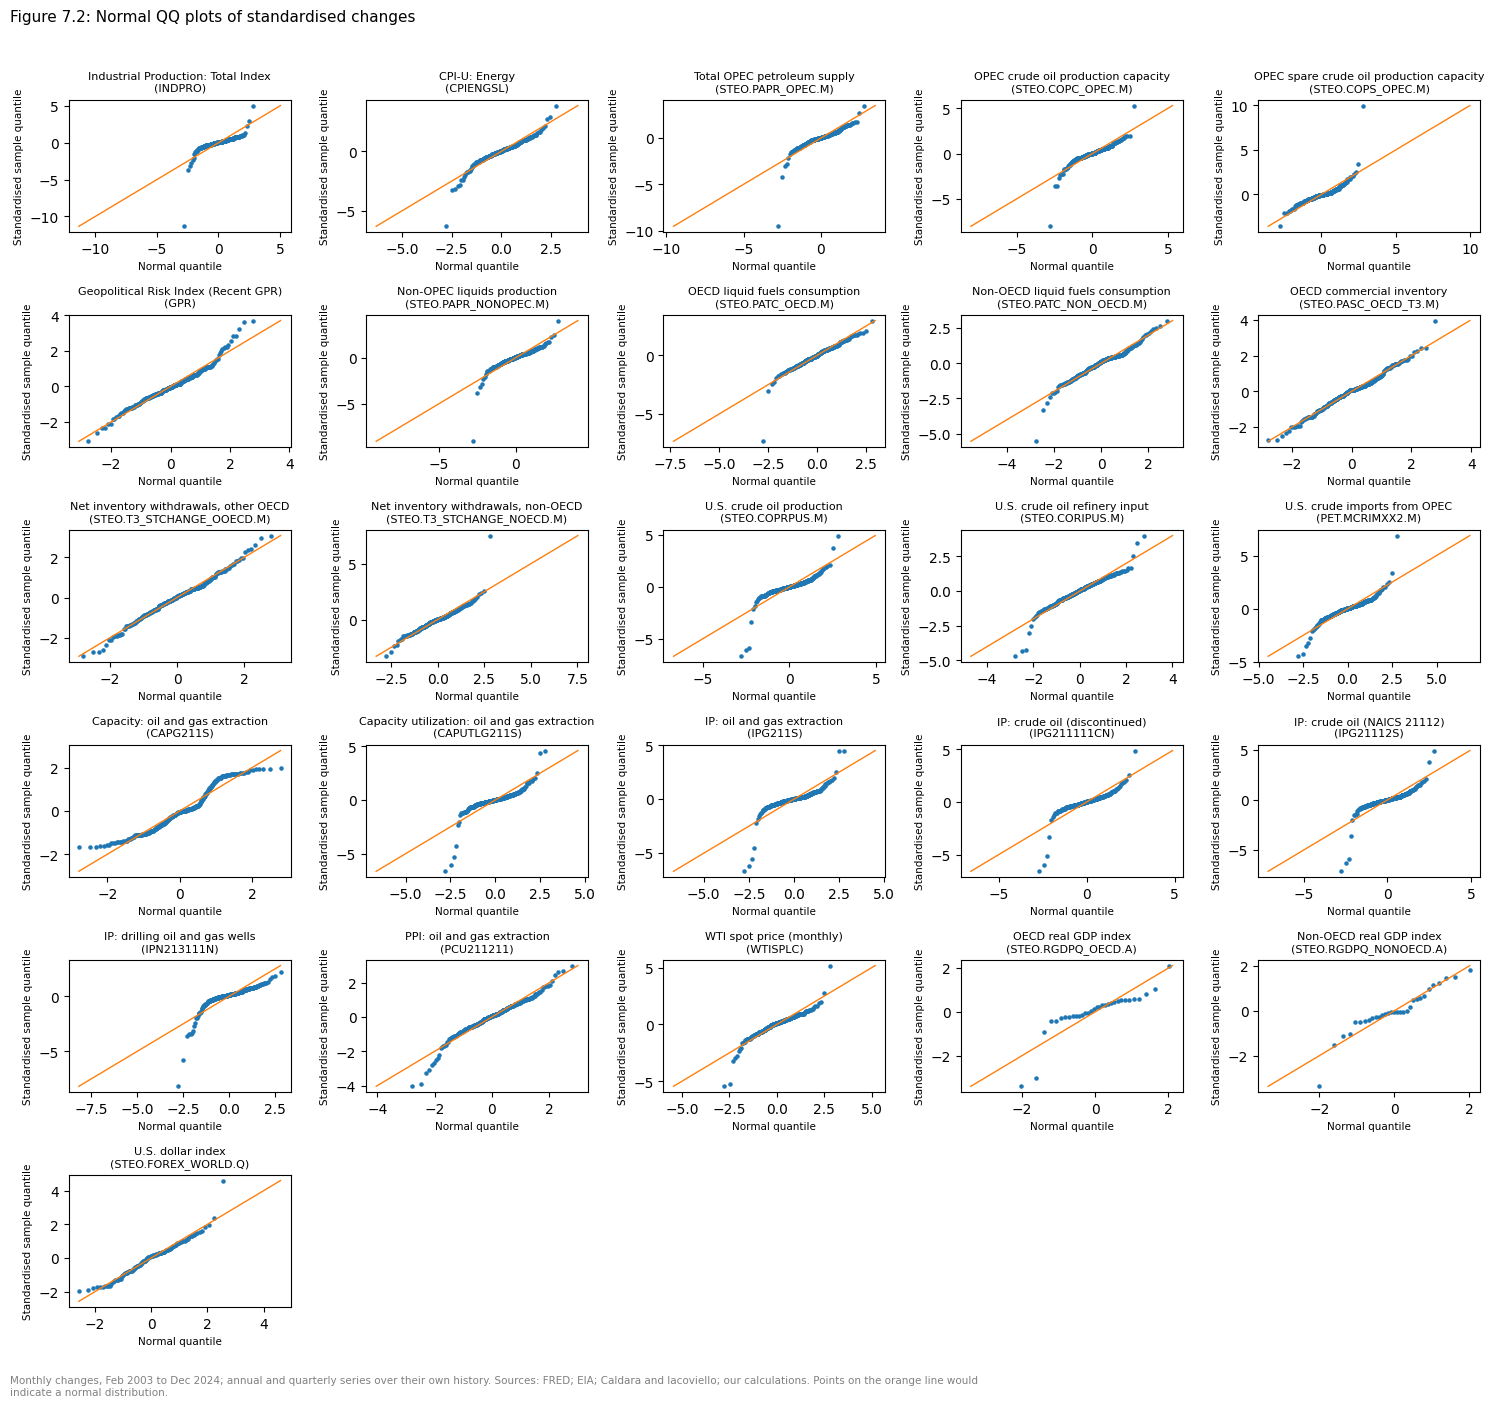

In [29]:
fig, axs = grid(len(dist_keys), ncols=5, w=3.0, h=2.3)
for ax, k in zip(axs, dist_keys):
    x = chg_m.get(k, chg_low.get(k))
    (osm, osr), _ = stats.probplot((x - x.mean()) / x.std(), dist="norm")
    ax.scatter(osm, osr, s=5, color="tab:blue")
    lim = [min(osm.min(), osr.min()), max(osm.max(), osr.max())]
    ax.plot(lim, lim, color="tab:orange", lw=1)
    ax.set_title(f"{SHORT[k]}\n({k})", fontsize=8)
    ax.set_xlabel("Normal quantile", fontsize=7.5)
    ax.set_ylabel("Standardised sample quantile", fontsize=7.5)
finish(fig, "Figure 7.2: Normal QQ plots of standardised changes", NOTE_M + " Points on the orange line would indicate a normal distribution.")

**Interpretation.** Figure 7.2 confirms Figure 7.1: for most series the points bend away from the 45-degree line at both ends, so the extreme changes are larger than a normal distribution allows. The furthest points belong to months already flagged in Step 5a, such as April and May 2020 (Table 5.2).

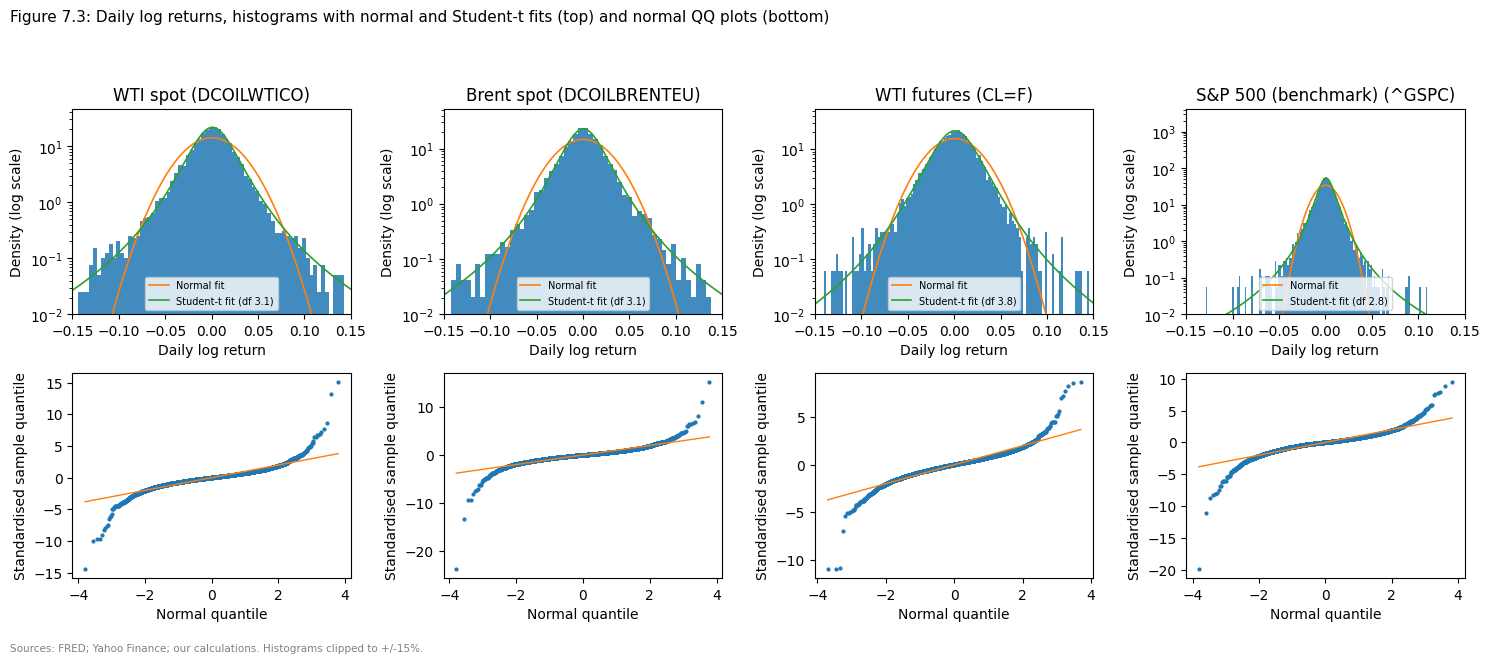

In [30]:
fig, axes = plt.subplots(2, 4, figsize=(15, 6.4))
for j, k in enumerate(daily_keys):
    x = rd[k]
    ax = axes[0, j]
    ax.hist(x, bins=200, density=True, color="tab:blue", alpha=0.85)
    g = np.linspace(-0.15, 0.15, 400)
    df_t, loc_t, sc_t = stats.t.fit(x)
    ax.plot(g, stats.norm.pdf(g, x.mean(), x.std()), color="tab:orange", lw=1.2, label="Normal fit")
    ax.plot(g, stats.t.pdf(g, df_t, loc_t, sc_t), color="tab:green", lw=1.2, label=f"Student-t fit (df {df_t:.1f})")
    ax.set_yscale("log")
    ax.set_ylim(1e-2, None)
    ax.set_xlim(-0.15, 0.15)
    ax.set_title(f"{D_LABEL[k]} ({k})")
    ax.set_xlabel("Daily log return")
    ax.set_ylabel("Density (log scale)")
    ax.legend(loc="lower center", fontsize=7)
    (osm, osr), _ = stats.probplot((x - x.mean()) / x.std(), dist="norm")
    axes[1, j].scatter(osm, osr, s=4, color="tab:blue")
    axes[1, j].plot([osm.min(), osm.max()], [osm.min(), osm.max()], color="tab:orange", lw=1)
    axes[1, j].set_xlabel("Normal quantile")
    axes[1, j].set_ylabel("Standardised sample quantile")
finish(fig, "Figure 7.3: Daily log returns, histograms with normal and Student-t fits (top) and normal QQ plots (bottom)",
       "Sources: FRED; Yahoo Finance; our calculations. Histograms clipped to +/-15%.")

**Interpretation.** Figure 7.3 shows the same pattern more strongly in daily returns. On the log density scale the normal curve falls far below the observed tails, while the Student-t curve, with between 2.8 and 3.8 degrees of freedom, follows them. The QQ plots show standardised returns beyond 10 standard deviations in every series, which a normal distribution would essentially never produce. The S&P 500 is fat-tailed too, so this is not unique to oil; Step 8 compares the series formally.

### Step 7b: Time-series plots

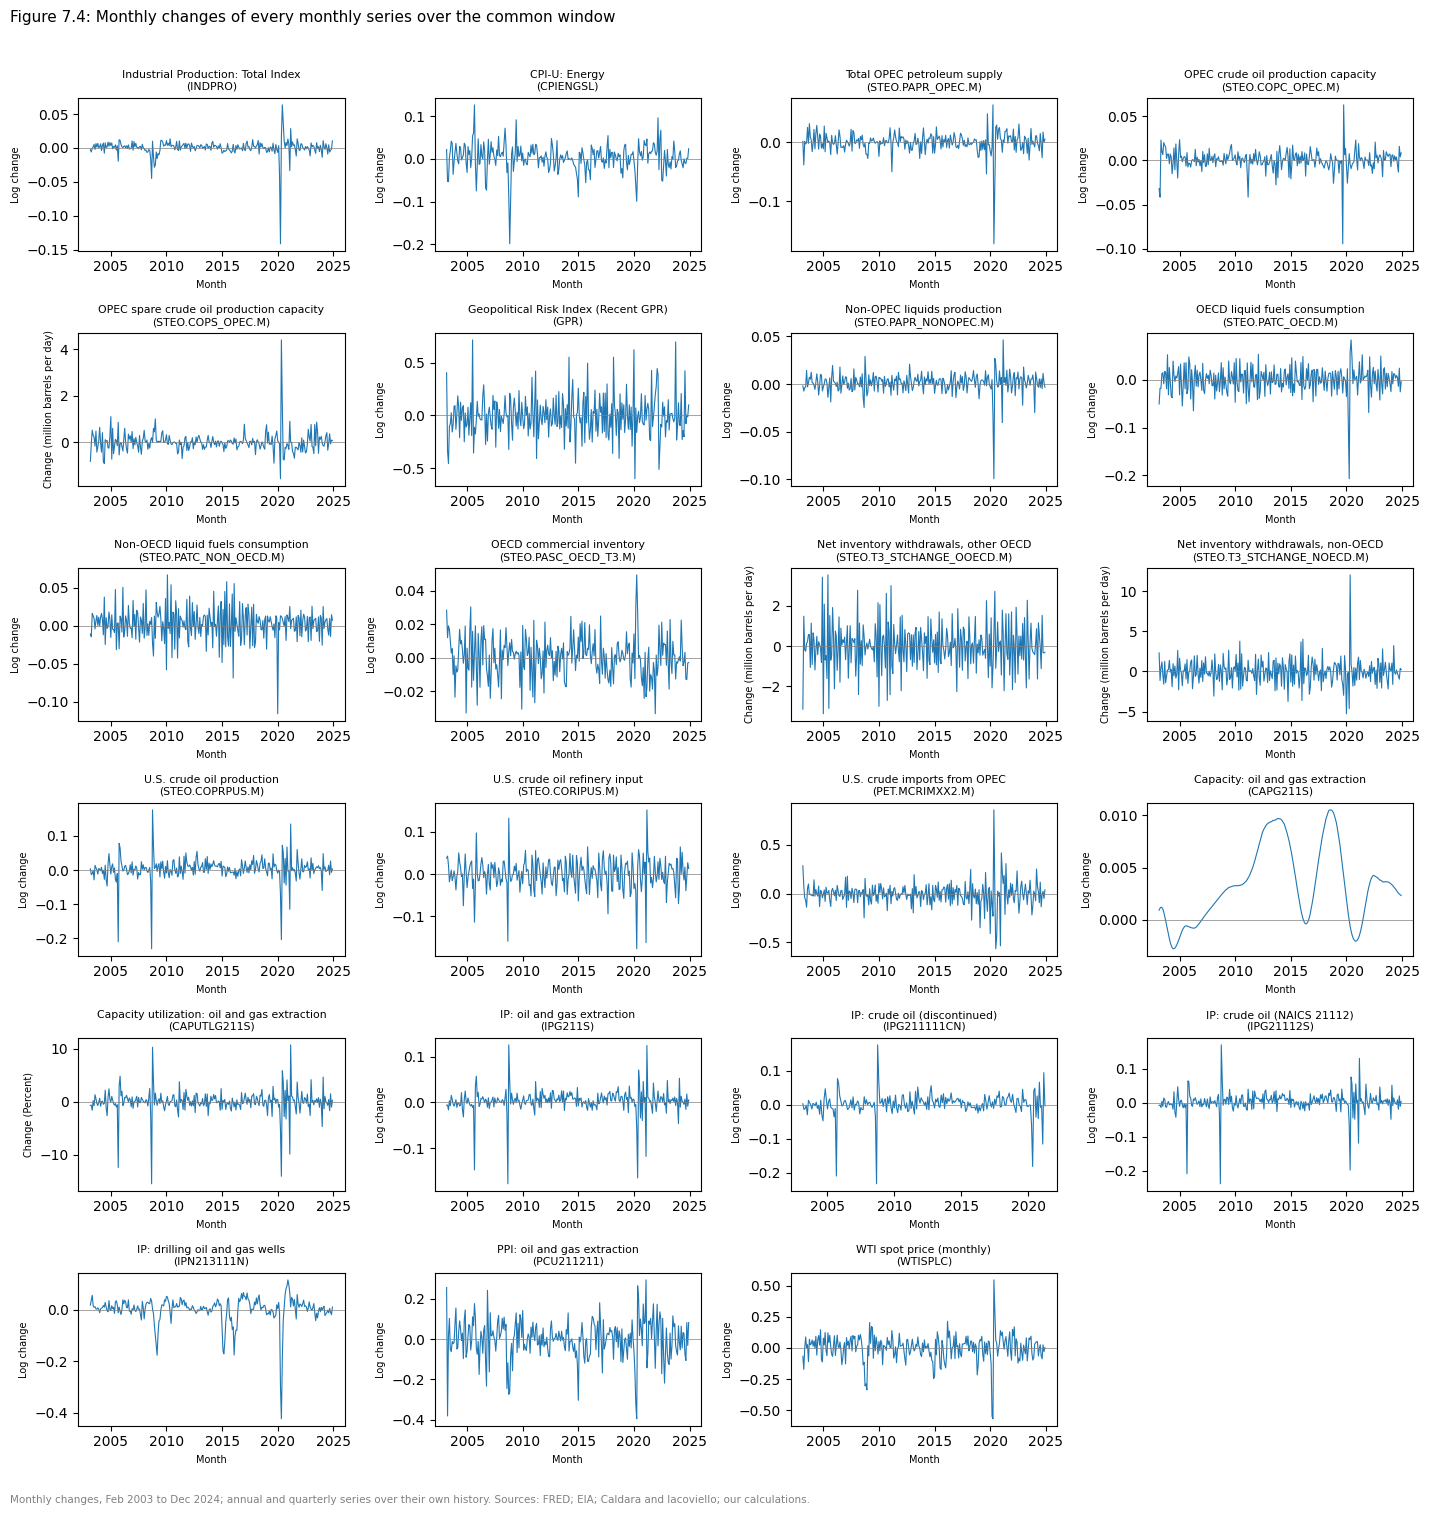

In [31]:
fig, axs = grid(len(monthly_keys), ncols=4, w=3.6, h=2.5)
for ax, k in zip(axs, monthly_keys):
    ax.plot(chg_m[k].index, chg_m[k].values, color="tab:blue", lw=0.8)
    ax.axhline(0, color="grey", lw=0.5)
    ax.set_title(f"{SHORT[k]}\n({k})", fontsize=7.8)
    ax.set_ylabel(chg_label(k), fontsize=7)
    ax.set_xlabel("Month", fontsize=7)
    year_axis(ax)
finish(fig, "Figure 7.4: Monthly changes of every monthly series over the common window", NOTE_M)

**Interpretation.** Figure 7.4 shows that the changes fluctuate around zero without trend, unlike the levels in Figures 3.1 and 3.3, and that the largest movements in supply, demand, production and prices coincide in late 2008 and in 2020. OECD consumption and U.S. refinery input show a regular saw-tooth pattern, a sign of seasonality that Step 8a tests.

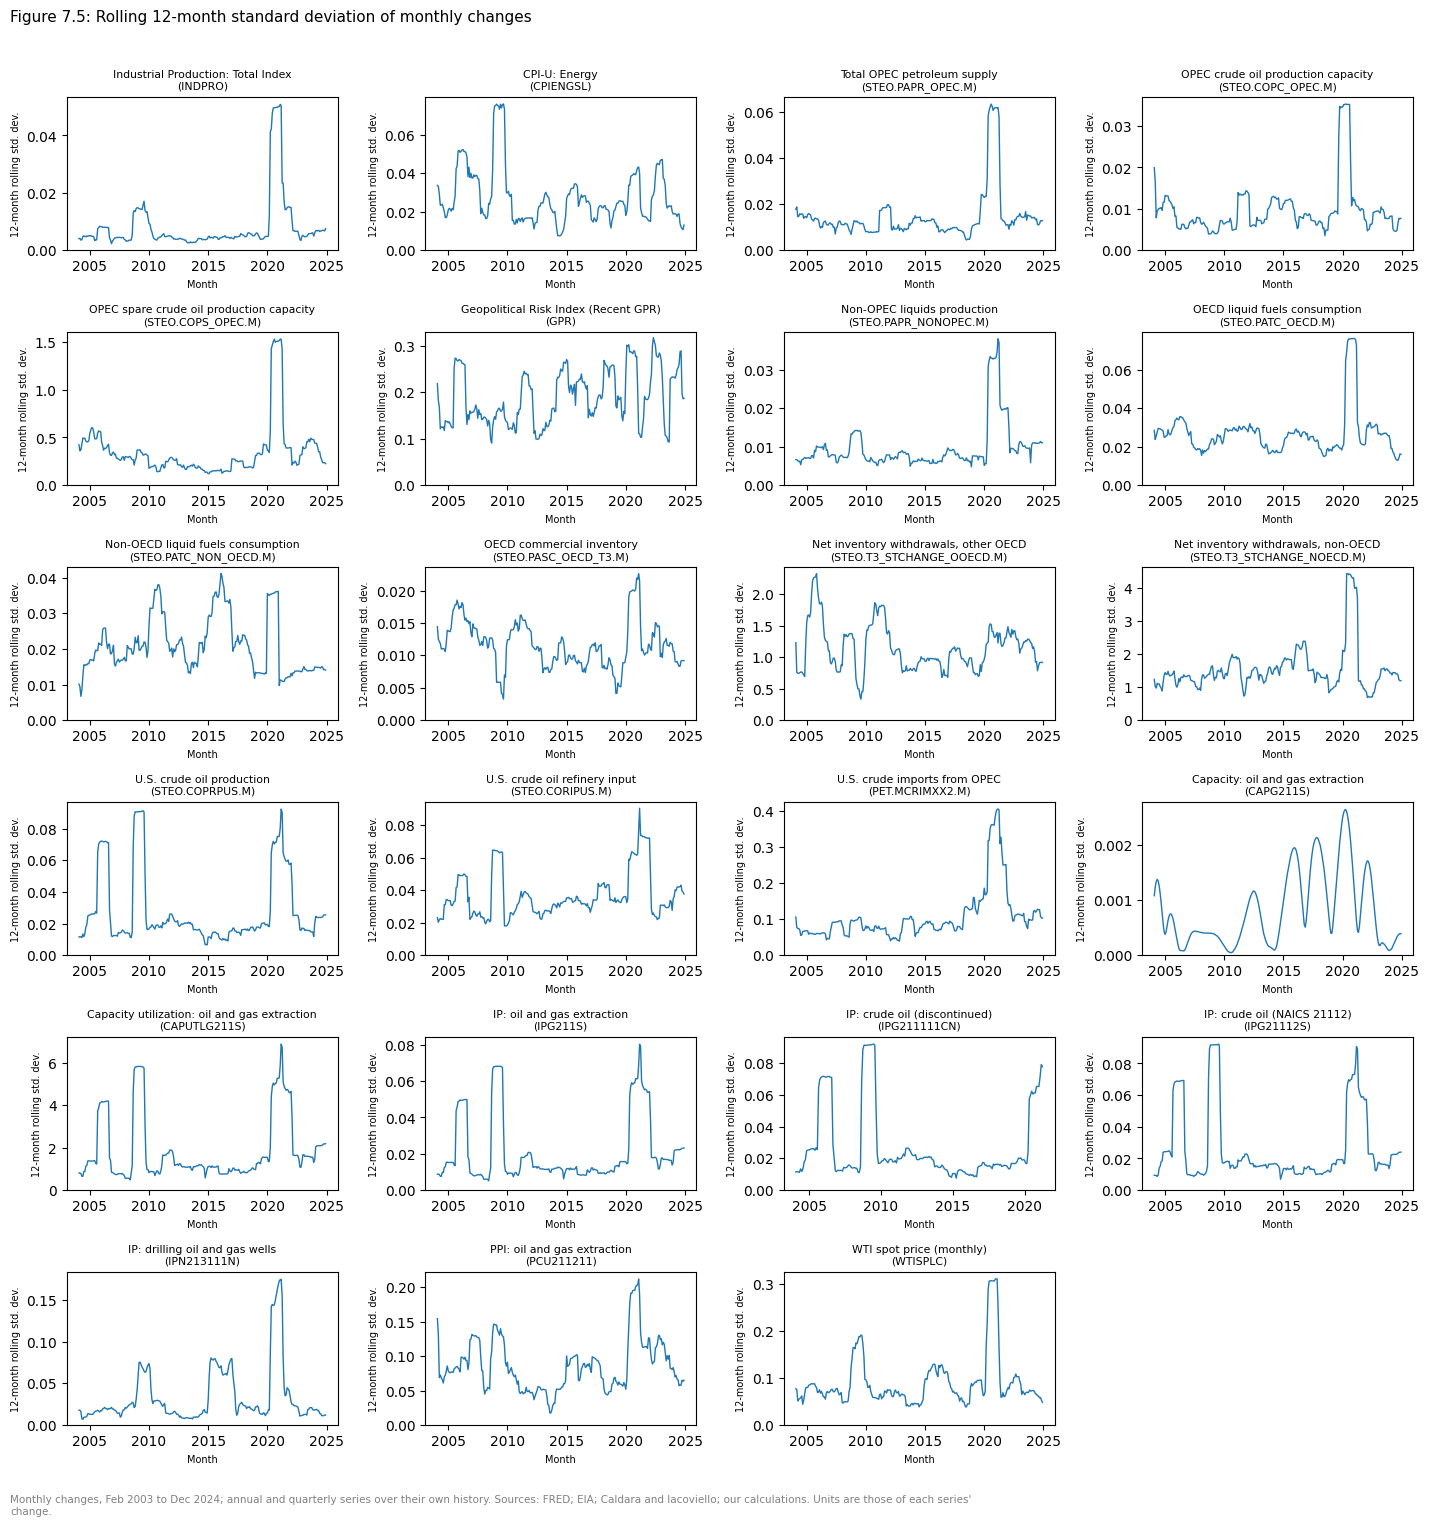

In [32]:
fig, axs = grid(len(monthly_keys), ncols=4, w=3.6, h=2.5)
for ax, k in zip(axs, monthly_keys):
    v = chg_m[k].rolling(12).std()
    ax.plot(v.index, v.values, color="tab:blue", lw=1)
    ax.set_title(f"{SHORT[k]}\n({k})", fontsize=7.8)
    ax.set_ylabel("12-month rolling std. dev.", fontsize=7)
    ax.set_xlabel("Month", fontsize=7)
    ax.set_ylim(0, None)
    year_axis(ax)
finish(fig, "Figure 7.5: Rolling 12-month standard deviation of monthly changes", NOTE_M + " Units are those of each series' change.")

**Interpretation.** Figure 7.5 shows that volatility is not constant. For most series the rolling standard deviation is low for long stretches and jumps in a few episodes, above all 2008 to 2009 and 2020 to 2021, before falling back. This bursty pattern is volatility clustering, which Step 8c tests formally.

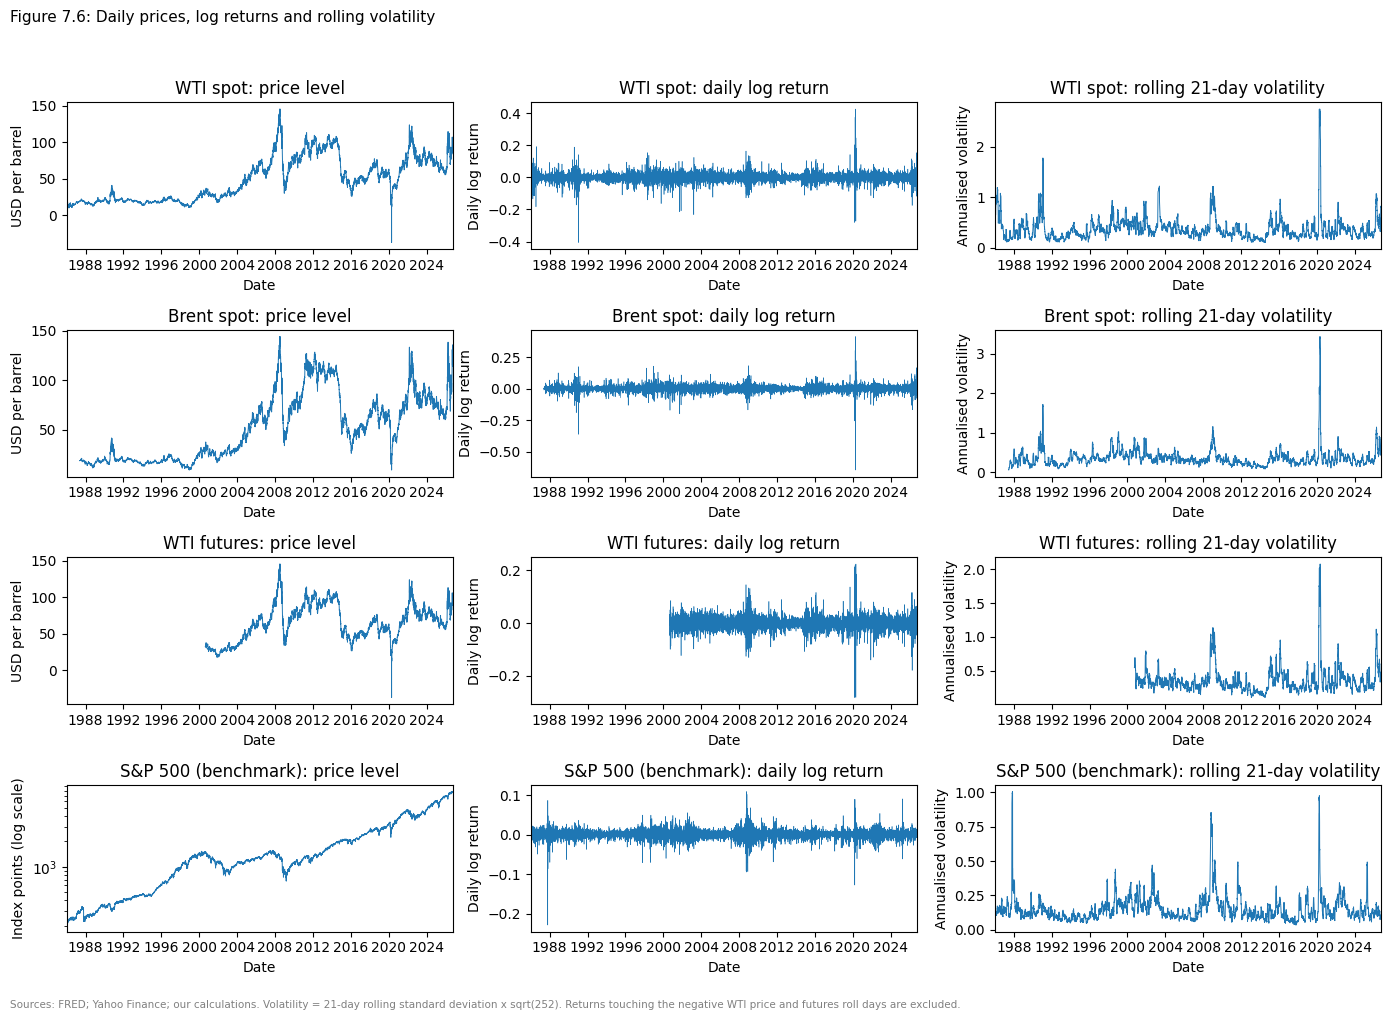

Table 7.1: Rolling 21-day annualised volatility


,median,maximum,date of maximum
WTI spot,0.325,2.749,2020-04-22
Brent spot,0.318,3.436,2020-04-29
WTI futures,0.312,2.078,2020-05-06
S&P 500 (benchmark),0.132,1.006,1987-11-12


In [33]:
fig, axes = plt.subplots(4, 3, figsize=(14, 10))
for i, k in enumerate(daily_keys):
    p = P[k].dropna()
    axes[i, 0].plot(p.index, p.values, color="tab:blue", lw=0.7)
    axes[i, 0].set_ylabel("USD per barrel" if k != "^GSPC" else "Index points (log scale)")
    if k == "^GSPC":
        axes[i, 0].set_yscale("log")
    axes[i, 0].set_title(f"{D_LABEL[k]}: price level")
    axes[i, 1].plot(rd[k].index, rd[k].values, color="tab:blue", lw=0.4)
    axes[i, 1].set_ylabel("Daily log return")
    axes[i, 1].set_title(f"{D_LABEL[k]}: daily log return")
    vol = rd[k].rolling(21).std() * np.sqrt(252)
    axes[i, 2].plot(vol.index, vol.values, color="tab:blue", lw=0.7)
    axes[i, 2].set_ylabel("Annualised volatility")
    axes[i, 2].set_title(f"{D_LABEL[k]}: rolling 21-day volatility")
    for a in axes[i]:
        a.set_xlabel("Date")
        a.set_xlim(pd.Timestamp("1986-01-01"), P.index.max())
finish(fig, "Figure 7.6: Daily prices, log returns and rolling volatility",
       "Sources: FRED; Yahoo Finance; our calculations. Volatility = 21-day rolling standard deviation x sqrt(252). Returns touching the negative WTI price and futures roll days are excluded.")
vol21 = {k: rd[k].rolling(21).std() * np.sqrt(252) for k in daily_keys}
print("Table 7.1: Rolling 21-day annualised volatility")
pd.DataFrame({D_LABEL[k]: {"median": round(v.median(), 3), "maximum": round(v.max(), 3), "date of maximum": v.idxmax().date()} for k, v in vol21.items()}).T

**Interpretation.** Figure 7.6 shows long calm periods in all four markets broken by short bursts of very high volatility. Table 7.1 quantifies the contrast: the median rolling volatility of WTI spot (0.325) is about two and a half times that of the S&P 500 (0.132), and all three oil series reach their maximum in spring 2020, at several times their median. The return panels show the largest oil moves bunched in that same episode.

### Step 7c: Multivariate plots

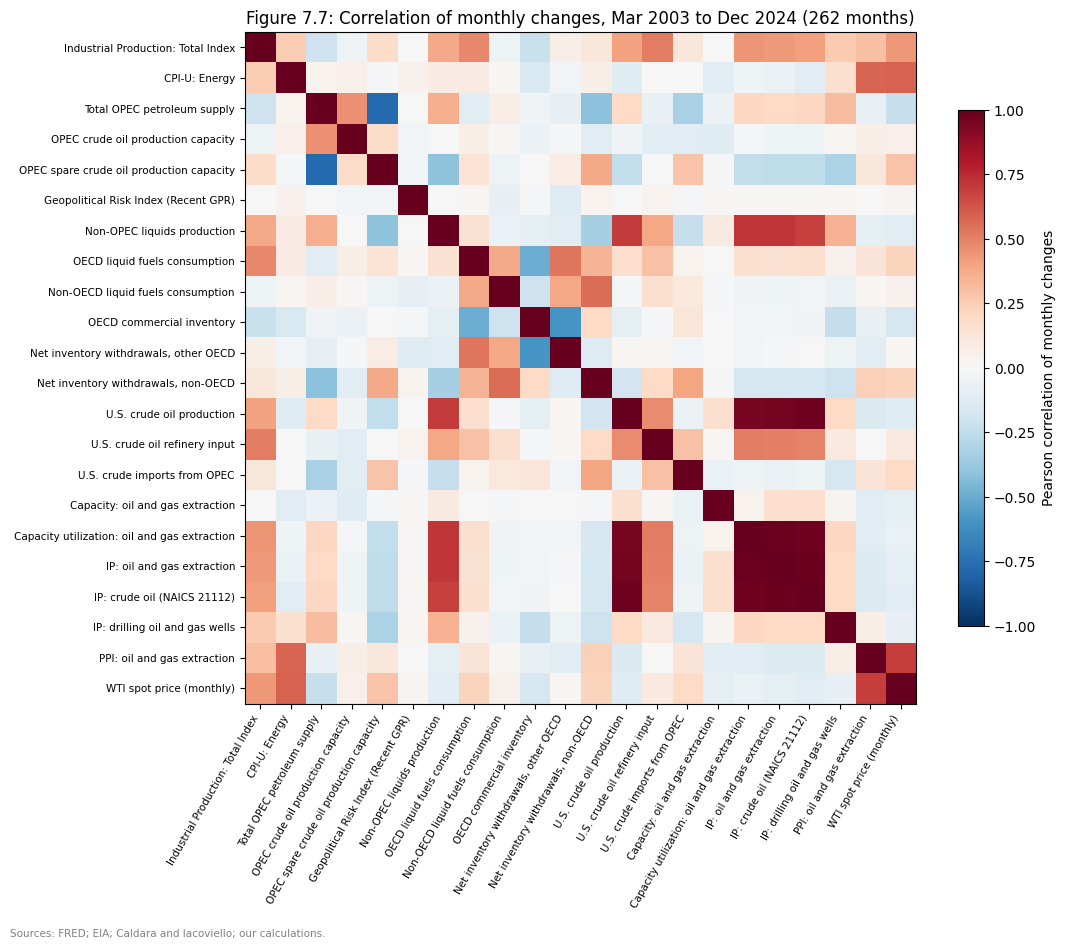

Table 7.2: Correlation of each variable's monthly change with the WTI monthly return


,Pearson,Spearman
PCU211211,0.694,0.644
CPIENGSL,0.586,0.559
INDPRO,0.436,0.086
STEO.COPS_OPEC.M,0.285,-0.022
STEO.PAPR_OPEC.M,-0.232,0.060
STEO.T3_STCHANGE_NOECD.M,0.223,0.012
STEO.PATC_OECD.M,0.219,-0.057
PET.MCRIMXX2.M,0.196,0.055
STEO.PASC_OECD_T3.M,-0.167,-0.088
STEO.COPRPUS.M,-0.125,-0.062


In [34]:
CH = pd.DataFrame({k: chg_m[k] for k in monthly_keys if k != "IPG211111CN"}).dropna()
corr = CH.corr()
fig, ax = plt.subplots(figsize=(11, 9.2))
im = ax.imshow(corr.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)))
ax.set_xticklabels([SHORT[k] for k in corr.columns], rotation=60, ha="right", fontsize=7.5)
ax.set_yticks(range(len(corr)))
ax.set_yticklabels([SHORT[k] for k in corr.columns], fontsize=7.5)
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.75).set_label("Pearson correlation of monthly changes")
ax.set_title(f"Figure 7.7: Correlation of monthly changes, {CH.index.min():%b %Y} to {CH.index.max():%b %Y} ({len(CH)} months)")
fig.tight_layout()
caption(fig, "Sources: FRED; EIA; Caldara and Iacoviello; our calculations.")
plt.show()

wti_corr = corr["WTISPLC"].drop("WTISPLC").sort_values(key=np.abs, ascending=False)
print("Table 7.2: Correlation of each variable's monthly change with the WTI monthly return")
pd.DataFrame({"Pearson": wti_corr, "Spearman": CH.corr(method="spearman")["WTISPLC"].reindex(wti_corr.index)}).round(3)

**Interpretation.** Figure 7.7 shows tight blocks among the U.S. production series (oil and gas extraction, crude oil, capacity utilization and U.S. crude production) and a strong negative link between OPEC supply and OPEC spare capacity, which EIA's identity in Step 5b implies. Table 7.2 shows that the variables most correlated with the WTI monthly return are other price series: the producer price index for oil and gas extraction (0.694) and the energy CPI (0.586). Physical supply, demand and inventory changes have correlations of 0.3 or less in absolute value. For several of them the rank (Spearman) correlation is close to zero although the Pearson correlation is not, for example industrial production (0.436 against 0.086) and OPEC spare capacity (0.285 against −0.022). A gap like this means that a few extreme months, rather than a steady relationship, produce the Pearson value.

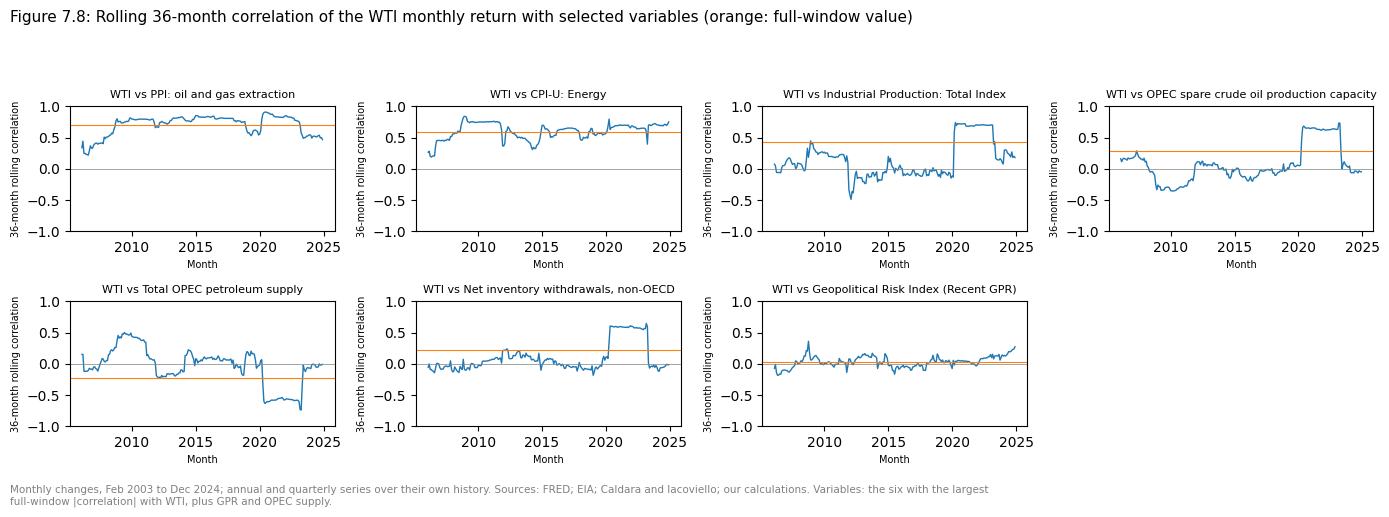

In [35]:
top_vars = wti_corr.index[:6].tolist() + [k for k in ["GPR", "STEO.PAPR_OPEC.M"] if k not in wti_corr.index[:6]]
fig, axs = grid(len(top_vars), ncols=4, w=3.5, h=2.4)
for ax, k in zip(axs, top_vars):
    rc = CH["WTISPLC"].rolling(36).corr(CH[k])
    ax.plot(rc.index, rc.values, color="tab:blue", lw=1)
    ax.axhline(0, color="grey", lw=0.5)
    ax.axhline(wti_corr[k], color="tab:orange", lw=0.8)
    ax.set_ylim(-1, 1)
    ax.set_title(f"WTI vs {SHORT[k]}", fontsize=8)
    ax.set_ylabel("36-month rolling correlation", fontsize=7)
    ax.set_xlabel("Month", fontsize=7)
    year_axis(ax)
finish(fig, "Figure 7.8: Rolling 36-month correlation of the WTI monthly return with selected variables (orange: full-window value)",
       NOTE_M + " Variables: the six with the largest full-window |correlation| with WTI, plus GPR and OPEC supply.")

**Interpretation.** Figure 7.8 confirms the reading of Table 7.2. The correlations of industrial production, OPEC spare capacity, OPEC supply and non-OECD inventory withdrawals with WTI jump abruptly when the extreme months of 2020 enter the 36-month window and fall back three years later when those months leave it. Only the two price series keep a stable positive correlation. The GPR index has a correlation with WTI close to zero throughout (0.026 over the full window, Table 7.2), so at a monthly frequency we find no stable linear link between measured geopolitical risk and oil price changes.

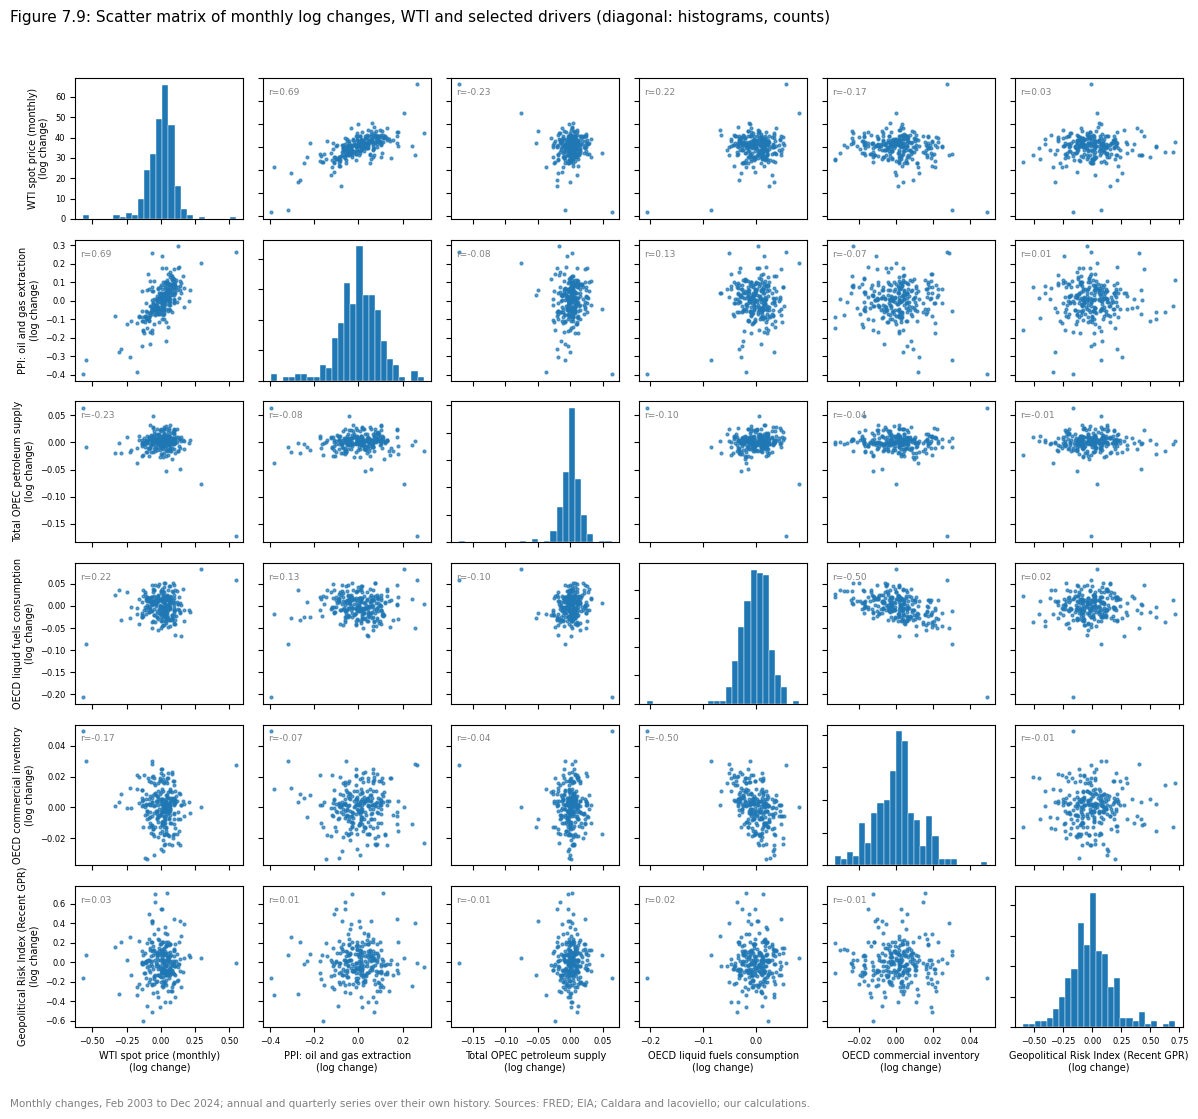

In [36]:
sm_keys = ["WTISPLC", "PCU211211", "STEO.PAPR_OPEC.M", "STEO.PATC_OECD.M", "STEO.PASC_OECD_T3.M", "GPR"]
fig, axes = plt.subplots(len(sm_keys), len(sm_keys), figsize=(12, 11))
for i, ky in enumerate(sm_keys):
    for j, kx in enumerate(sm_keys):
        ax = axes[i, j]
        if i == j:
            ax.hist(CH[kx], bins=25, color="tab:blue", edgecolor="white", linewidth=0.3)
        else:
            ax.scatter(CH[kx], CH[ky], s=4, color="tab:blue", alpha=0.7)
            ax.text(0.03, 0.93, f"r={corr.loc[ky, kx]:.2f}", transform=ax.transAxes, fontsize=6.5, color="grey", va="top")
        if i == len(sm_keys) - 1:
            ax.set_xlabel(f"{SHORT[kx]}\n(log change)", fontsize=7)
        else:
            ax.set_xticklabels([])
        if j == 0:
            ax.set_ylabel(f"{SHORT[ky]}\n(log change)", fontsize=7)
        else:
            ax.set_yticklabels([])
        ax.tick_params(labelsize=6)
finish(fig, "Figure 7.9: Scatter matrix of monthly log changes, WTI and selected drivers (diagonal: histograms, counts)", NOTE_M)

**Interpretation.** Figure 7.9 shows the WTI return lined up with the producer price index (r = 0.69), while its scatter plots against OPEC supply, OECD consumption, OECD inventories and GPR are shapeless clouds with a few outlying points. These points are the extreme months that drive the Pearson correlations in Table 7.2.

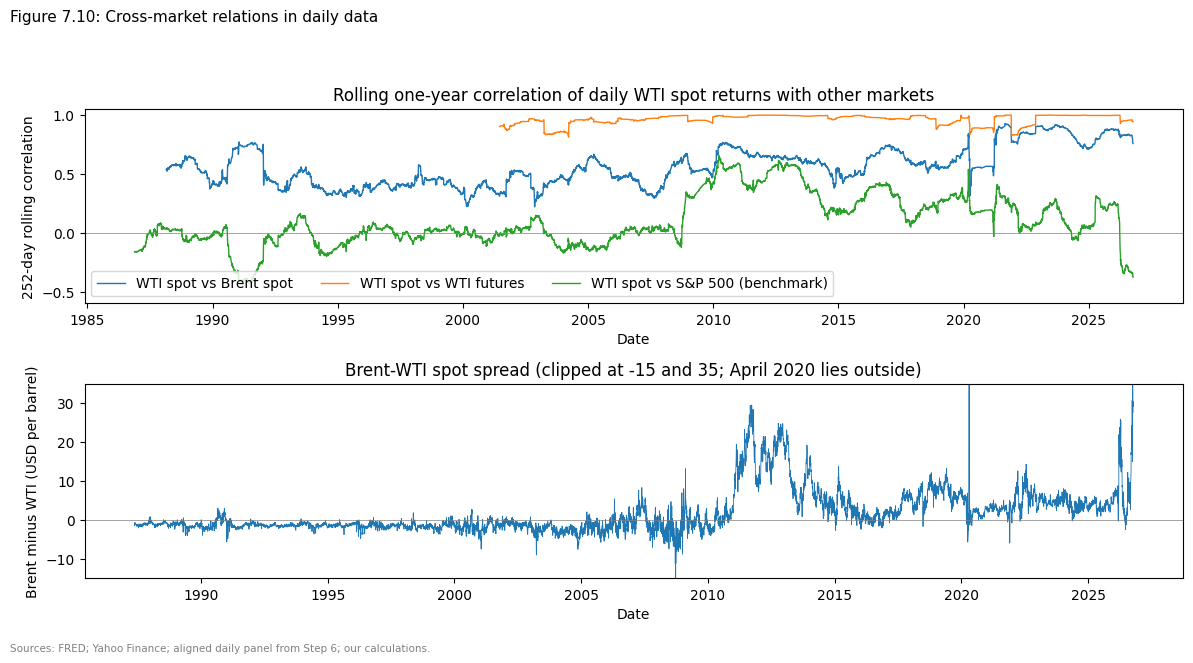

Table 7.3a: Rolling one-year correlation of daily WTI spot returns with each market


,min,date of min,max,date of max
Brent spot,0.22,2002-11-13,0.93,2021-08-27
WTI futures,0.81,2004-03-23,1.00,2024-11-19
S&P 500 (benchmark),-0.43,1991-01-23,0.65,2010-03-25


Table 7.3b: Mean Brent-WTI spread by period (USD per barrel)


,mean spread
1987-2010,-1.38
2011-2014,12.59
2015-2026,4.37


In [37]:
A = S["daily_aligned_prices"]
AR = np.log(A.where(A > 0)).diff()
AR.loc[AR.index.isin(roll_days), "CL=F"] = np.nan
fig, axes = plt.subplots(2, 1, figsize=(12, 6.4))
for k, c in [("DCOILBRENTEU", "tab:blue"), ("CL=F", "tab:orange"), ("^GSPC", "tab:green")]:
    rc = AR["DCOILWTICO"].rolling(252, min_periods=200).corr(AR[k])
    axes[0].plot(rc.index, rc.values, color=c, lw=1, label=f"WTI spot vs {D_LABEL[k]}")
axes[0].axhline(0, color="grey", lw=0.5)
axes[0].set_ylim(-0.6, 1.05)
axes[0].set_ylabel("252-day rolling correlation")
axes[0].set_xlabel("Date")
axes[0].set_title("Rolling one-year correlation of daily WTI spot returns with other markets")
axes[0].legend(loc="lower left", ncol=3)
spread = (A["DCOILBRENTEU"] - A["DCOILWTICO"]).dropna()
axes[1].plot(spread.index, spread.values, color="tab:blue", lw=0.6)
axes[1].axhline(0, color="grey", lw=0.5)
axes[1].set_ylim(-15, 35)
axes[1].set_ylabel("Brent minus WTI (USD per barrel)")
axes[1].set_xlabel("Date")
axes[1].set_title("Brent-WTI spot spread (clipped at -15 and 35; April 2020 lies outside)")
finish(fig, "Figure 7.10: Cross-market relations in daily data", "Sources: FRED; Yahoo Finance; aligned daily panel from Step 6; our calculations.")

roll = pd.DataFrame({D_LABEL[k]: AR["DCOILWTICO"].rolling(252, min_periods=200).corr(AR[k]) for k in ["DCOILBRENTEU", "CL=F", "^GSPC"]})
print("Table 7.3a: Rolling one-year correlation of daily WTI spot returns with each market")
display(pd.DataFrame({"min": roll.min(), "date of min": roll.idxmin().dt.date, "max": roll.max(), "date of max": roll.idxmax().dt.date}).round(2))
print("Table 7.3b: Mean Brent-WTI spread by period (USD per barrel)")
spread.groupby(pd.cut(spread.index.year, [1986, 2010, 2014, 2026], labels=["1987-2010", "2011-2014", "2015-2026"]), observed=True).mean().round(2).to_frame("mean spread")

**Interpretation.** Figure 7.10 and Tables 7.3a and 7.3b show that oil markets move together but not identically. Table 7.3a shows that the rolling correlation of WTI spot with WTI futures stays between 0.81 and 1.00, while the correlation with Brent ranges from 0.22 to 0.93. The correlation of oil with the S&P 500 changes sign, from −0.43 in January 1991 to 0.65 in March 2010, so oil is not a stable diversifier for equities. Table 7.3b shows that the Brent-WTI spread shifted level over time: Brent averaged \$1.38 below WTI over 1987 to 2010, \$12.59 above it over 2011 to 2014 and \$4.37 above it since 2015.

## Step 8: Questions on the cleaned data

We answered the four questions with daily log returns of WTI spot, Brent spot and WTI front-month futures (roll days excluded), using the S&P 500 as a non-oil benchmark, and with monthly WTI returns from January 1986. Step 5b showed that `WTISPLC` is the monthly mean of daily prices (Table 5.8b), and averaging alone can create autocorrelation, so we built the monthly S&P 500 benchmark the same way and also tested end-of-month WTI returns. Following Cont (2001), we treat "stylized facts" as statistical properties of returns, such as their distribution, tails and dependence over time, that are common to many markets and instruments. We answer 8b and 8c first, because the answer to 8a draws on their results.

In [38]:
wti_m = MC["WTISPLC"]["1985-12-01":].dropna()
wti_eom = P["DCOILWTICO"].dropna().resample("MS").last()
rm = {"WTI monthly (avg)": np.log(wti_m).diff().dropna(),
      "S&P 500 monthly (avg)": np.log(P["^GSPC"].dropna().resample("MS").mean()["1985-12-01":]).diff().dropna(),
      "WTI monthly (end of month)": np.log(wti_eom.where(wti_eom > 0)).diff().dropna()}
series8 = {"WTI spot daily": rd["DCOILWTICO"], "Brent spot daily": rd["DCOILBRENTEU"],
           "WTI futures daily": rd["CL=F"], "S&P 500 daily": rd["^GSPC"], **rm}
print("Table 8.1: Return series used in Step 8")
pd.DataFrame({k: {"from": v.index.min().date(), "to": v.index.max().date(), "n": len(v)} for k, v in series8.items()}).T

Table 8.1: Return series used in Step 8


,from,to,n
WTI spot daily,1986-01-03,2026-10-06,9514
Brent spot daily,1987-05-21,2026-10-06,9101
WTI futures daily,2000-08-25,2026-10-08,6342
S&P 500 daily,1986-01-03,2026-10-08,10270
WTI monthly (avg),1986-01-01,2026-09-01,489
S&P 500 monthly (avg),1986-02-01,2026-10-01,489
WTI monthly (end of month),1986-02-01,2026-10-01,489


### Step 8b: What types of distributions do oil returns have?

We computed summary moments, the Jarque-Bera test of normality (Jarque & Bera, 1987), and fitted a normal and a Student-t distribution by maximum likelihood, compared by the Akaike information criterion, where lower is better (Akaike, 1974). We also counted returns more than 3 and 5 standard deviations from the mean, against the frequencies a normal distribution implies.

In [39]:
def describe_returns(x, periods):
    jb = stats.jarque_bera(x)
    df_t, loc_t, sc_t = stats.t.fit(x)
    ll_n = stats.norm.logpdf(x, x.mean(), x.std(ddof=0)).sum()
    ll_t = stats.t.logpdf(x, df_t, loc_t, sc_t).sum()
    z = (x - x.mean()) / x.std()
    return {"n": len(x), "ann. mean": x.mean() * periods, "ann. vol": x.std() * np.sqrt(periods),
            "skewness": stats.skew(x), "excess kurtosis": stats.kurtosis(x), "min": x.min(), "max": x.max(),
            "JB stat": jb.statistic, "JB p": jb.pvalue, "t df": df_t, "AIC normal": 4 - 2 * ll_n, "AIC t": 6 - 2 * ll_t,
            "% beyond 3 sd": 100 * (z.abs() > 3).mean(), "count beyond 5 sd": int((z.abs() > 5).sum()),
            "normal: expected beyond 5 sd": len(x) * 2 * stats.norm.sf(5)}

dist_table = pd.DataFrame({k: describe_returns(v, 252 if "daily" in k else 12) for k, v in series8.items()}).T
print(f"Table 8.2: Distribution of log returns (under a normal, {100 * 2 * stats.norm.sf(3):.2f}% of returns lie beyond 3 sd)")
dist_table.round(4)

Table 8.2: Distribution of log returns (under a normal, 0.27% of returns lie beyond 3 sd)


,n,ann. mean,ann. vol,skewness,excess kurtosis,min,max,JB stat,JB p,t df,AIC normal,AIC t,% beyond 3 sd,count beyond 5 sd,normal: expected beyond 5 sd
WTI spot daily,9514.0,0.0542,0.4480,-0.1643,22.9157,-0.4064,0.4258,2.082121e+05,0.0,3.0703,-40884.2165,-43970.0582,1.5030,27.0,0.0055
Brent spot daily,9101.0,0.0528,0.4288,-1.4963,53.3078,-0.6437,0.4120,1.081002e+06,0.0,3.1056,-39906.8327,-43113.6520,1.2526,25.0,0.0052
WTI futures daily,6342.0,0.0567,0.4089,-0.3597,12.9741,-0.2822,0.2239,4.461714e+04,0.0,3.7626,-28411.0328,-29808.1505,1.4822,17.0,0.0036
S&P 500 daily,10270.0,0.0886,0.1834,-1.1260,24.9309,-0.2290,0.1096,2.681422e+05,0.0,2.8028,-62477.8560,-65661.4581,1.4314,35.0,0.0059
WTI monthly (avg),489.0,0.0313,0.3374,-0.5604,7.0098,-0.5681,0.5456,1.026771e+03,0.0,3.9441,-886.9888,-985.8056,1.6360,3.0,0.0003
S&P 500 monthly (avg),489.0,0.0888,0.1258,-1.5824,6.9773,-0.2281,0.1135,1.195986e+03,0.0,3.6590,-1851.6887,-1947.6055,1.4315,2.0,0.0003
WTI monthly (end of month),489.0,0.0391,0.3738,-0.4609,8.2892,-0.7820,0.6150,1.417290e+03,0.0,4.2002,-786.7007,-876.4792,1.4315,2.0,0.0003


**Answer 8b.** Table 8.2 shows that oil returns are **not normal: they are fat-tailed and negatively skewed**, and a Student-t distribution with three to four degrees of freedom describes them far better than a normal.

* The Jarque-Bera test rejects normality for every series (Table 8.2, `JB p`).
* Daily excess kurtosis is 22.9 for WTI spot, 53.3 for Brent and 13.0 for WTI futures, and skewness is negative for all three (−0.16, −1.50, −0.36).
* The Student-t fits have 3.1, 3.1 and 3.8 degrees of freedom and much lower AIC than the normal fits.
* Returns beyond 3 standard deviations occur 1.25% to 1.50% of the time in the oil series, about five times the normal rate of 0.27%. Returns beyond 5 standard deviations occur 17 to 27 times per series, where a normal distribution would expect about 0.005.
* Fat tails are not unique to oil: the S&P 500 also has large excess kurtosis (24.9) and a Student-t fit with 2.8 degrees of freedom, which is consistent with Cont's description of tail properties as common to many markets (Cont, 2001). What separates oil is scale: annualised volatility is 0.45 for WTI spot against 0.18 for the S&P 500.
* At the monthly horizon the tails are thinner but still fat (excess kurtosis 7.0 for WTI), and normality is still rejected.

### Step 8c: What type of autocorrelation do oil returns have?

We plotted the ACF and PACF and applied the Ljung-Box test (Ljung & Box, 1978) to returns, squared returns and absolute returns, and Engle's ARCH-LM test for conditional heteroskedasticity (Engle, 1982). Returns test whether the direction of moves is predictable; squared and absolute returns test whether their size is.

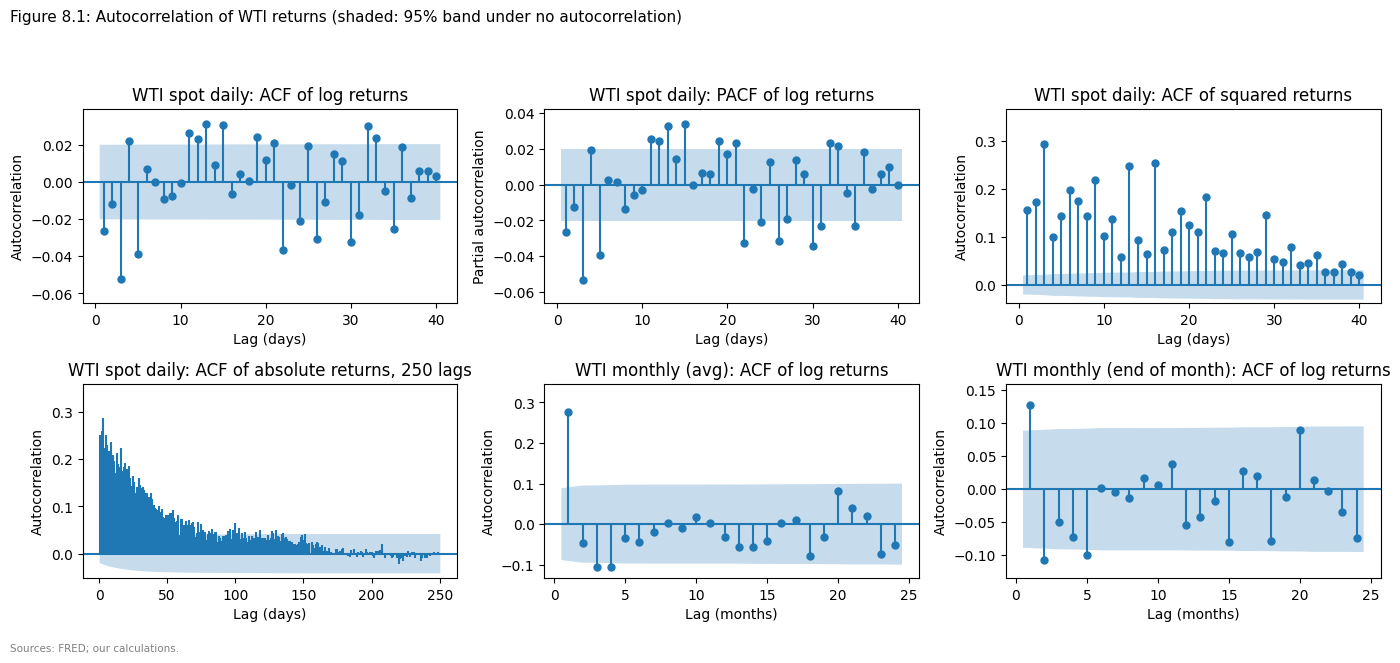

ACF of |r| (WTI spot daily): lag 1 0.251, lag 20 0.179, lag 100 0.065, lag 250 0.002; 95% band +/-0.020


In [40]:
x = rd["DCOILWTICO"]
fig, axes = plt.subplots(2, 3, figsize=(14, 6.4))
kw = dict(zero=False, color="tab:blue", vlines_kwargs={"colors": "tab:blue"}, auto_ylims=True)
plot_acf(x, lags=40, ax=axes[0, 0], **kw)
axes[0, 0].set_title("WTI spot daily: ACF of log returns")
plot_pacf(x, lags=40, ax=axes[0, 1], method="ywm", **kw)
axes[0, 1].set_title("WTI spot daily: PACF of log returns")
plot_acf(x ** 2, lags=40, ax=axes[0, 2], **kw)
axes[0, 2].set_title("WTI spot daily: ACF of squared returns")
plot_acf(x.abs(), lags=250, ax=axes[1, 0], marker=None, **kw)
axes[1, 0].set_title("WTI spot daily: ACF of absolute returns, 250 lags")
plot_acf(rm["WTI monthly (avg)"], lags=24, ax=axes[1, 1], **kw)
axes[1, 1].set_title("WTI monthly (avg): ACF of log returns")
plot_acf(rm["WTI monthly (end of month)"], lags=24, ax=axes[1, 2], **kw)
axes[1, 2].set_title("WTI monthly (end of month): ACF of log returns")
for ax in axes.flat:
    ax.set_xlabel("Lag (days)" if "daily" in ax.get_title() else "Lag (months)")
    ax.set_ylabel("Partial autocorrelation" if "PACF" in ax.get_title() else "Autocorrelation")
finish(fig, "Figure 8.1: Autocorrelation of WTI returns (shaded: 95% band under no autocorrelation)", "Sources: FRED; our calculations.")
acf_abs = acf(x.abs(), nlags=250, fft=True)
print(f"ACF of |r| (WTI spot daily): lag 1 {acf_abs[1]:.3f}, lag 20 {acf_abs[20]:.3f}, lag 100 {acf_abs[100]:.3f}, "
      f"lag 250 {acf_abs[250]:.3f}; 95% band +/-{1.96 / np.sqrt(len(x)):.3f}")

**Interpretation.** Figure 8.1 shows that the daily return autocorrelations are tiny, at most about 0.05 in absolute value, while the autocorrelations of squared and absolute returns are large and positive at every lag shown. The output adds that the ACF of absolute returns is 0.251 at lag 1, 0.179 at lag 20 and 0.065 at lag 100, all above the 95% band of 0.020, and has died out by lag 250 (0.002). Volatility shocks therefore fade slowly, over months rather than days. For monthly WTI, the series built from averages has a clear lag-1 spike, while the end-of-month series has a much smaller one.

In [41]:
def lb(x, lags):
    t = acorr_ljungbox(x, lags=lags, return_df=True)
    return {f"Q({l})": t.loc[l, "lb_stat"] for l in lags} | {f"p({l})": t.loc[l, "lb_pvalue"] for l in lags}

rows = {}
for k, v in series8.items():
    lags, nl = ([20], 10) if "daily" in k else ([12], 6)
    v = v - v.mean()
    row = {"lag-1 autocorr.": v.autocorr(1)}
    row |= {f"returns {a}": b for a, b in lb(v, lags).items()}
    row |= {f"squared {a}": b for a, b in lb(v ** 2, lags).items()}
    row |= {f"absolute {a}": b for a, b in lb(v.abs(), lags).items()}
    lm, lmp, _, _ = het_arch(v, nlags=nl)
    rows[k] = row | {"ARCH-LM lags": nl, "ARCH-LM stat": lm, "ARCH-LM p": lmp}
print("Table 8.3: Ljung-Box (20 lags daily, 12 lags monthly) and ARCH-LM tests")
pd.DataFrame(rows).T.map(lambda v: f"{v:.4g}" if isinstance(v, float) else v)

Table 8.3: Ljung-Box (20 lags daily, 12 lags monthly) and ARCH-LM tests


,lag-1 autocorr.,returns Q(20),returns p(20),squared Q(20),squared p(20),absolute Q(20),absolute p(20),ARCH-LM lags,ARCH-LM stat,ARCH-LM p,returns Q(12),returns p(12),squared Q(12),squared p(12),absolute Q(12),absolute p(12)
WTI spot daily,-0.02623,93.18,2.052e-11,5141,0,8979,0,10,1409,1.418e-296,nan,nan,nan,nan,nan,nan
Brent spot daily,-0.002895,73.98,4.024e-08,2479,0,6874,0,10,1308,7.441e-275,nan,nan,nan,nan,nan,nan
WTI futures daily,-0.02806,78.58,6.836e-09,4180,0,5924,0,10,1110,2.992e-232,nan,nan,nan,nan,nan,nan
S&P 500 daily,-0.06499,136.1,2.749e-19,3209,0,1.274e+04,0,10,1199,2.343e-251,nan,nan,nan,nan,nan,nan
WTI monthly (avg),0.278,nan,nan,nan,nan,nan,nan,6,208.7,2.702e-42,52.37,5.33e-07,239.6,2.047e-44,136.7,2.716e-23
S&P 500 monthly (avg),0.225,nan,nan,nan,nan,nan,nan,6,14.02,0.02946,31.3,0.001771,19.08,0.08673,66.61,1.374e-09
WTI monthly (end of month),0.1293,nan,nan,nan,nan,nan,nan,6,84.42,4.348e-16,24.9,0.01528,74.92,3.812e-11,66.89,1.22e-09


**Answer 8c.** Table 8.3 shows that oil returns have **almost no linear autocorrelation but strong and persistent autocorrelation in their size, that is, volatility clustering**.

* **Returns.** Daily lag-1 autocorrelations are close to zero (−0.026 WTI spot, −0.003 Brent, −0.028 futures). The Ljung-Box test still rejects "no autocorrelation" for every daily series, the S&P 500 included, because with about 9,000 observations even very small autocorrelations are statistically significant. In our judgement they are too small to offer useful forecasting power.
* **Squared and absolute returns.** The Ljung-Box statistics run into the thousands with p-values of zero, and the ARCH-LM statistics exceed 1,100 with p-values below 1e-230 for every daily oil series, so large moves follow large moves.
* **Persistence.** Figure 8.1 shows that this dependence lasts for months.
* **Monthly, and a warning about Alvi's target.** The averaged WTI series has a lag-1 autocorrelation of 0.28, but the S&P 500 built the same way has 0.23, while end-of-month WTI returns have 0.13. Roughly half of the monthly persistence in `WTISPLC` therefore comes from averaging rather than from the market. A model that forecasts the next month of `WTISPLC`, as Alvi's does (Alvi, 2018), will partly be predicting this averaging effect.

### Step 8a: What makes oil prices look different from other asset prices?

We compared the oil series with the S&P 500 on spikes, stationarity and seasonality. For stationarity we used the augmented Dickey-Fuller test, whose null hypothesis is a unit root (Dickey & Fuller, 1979), and the KPSS test, whose null is stationarity (Kwiatkowski et al., 1992). For seasonality we used the Kruskal-Wallis rank test of equal distributions across calendar months (Kruskal & Wallis, 1952) and a one-way analysis of variance.

In [42]:
top = rd["DCOILWTICO"].abs().sort_values(ascending=False).head(10).index
print("Table 8.4: Ten largest absolute daily WTI spot log returns, with same-day returns elsewhere (aligned panel)")
pd.DataFrame({"WTI spot": rd["DCOILWTICO"].reindex(top), "Brent spot": AR["DCOILBRENTEU"].reindex(top),
              "WTI futures": AR["CL=F"].reindex(top), "S&P 500": AR["^GSPC"].reindex(top)}).round(4).rename(index=lambda d: d.date())

Table 8.4: Ten largest absolute daily WTI spot log returns, with same-day returns elsewhere (aligned panel)


,WTI spot,Brent spot,WTI futures,S&P 500
date,,,,
2020-04-22,0.4258,0.4120,NaN,0.0227
1991-01-17,-0.4064,-0.3612,NaN,0.0366
2020-03-31,0.3747,-0.2564,0.0192,-0.0161
2020-03-09,-0.2814,-0.2552,-0.2822,-0.0790
2020-03-18,-0.2749,-0.2048,-0.2799,-0.0532
2020-04-27,-0.2730,-0.0451,-0.2818,0.0146
2020-03-20,-0.2531,0.0634,-0.1172,-0.0443
2020-04-30,0.2458,0.0139,0.2239,-0.0093
2003-03-19,-0.2326,-0.0053,-0.0582,0.0087


**Interpretation.** Table 8.4 shows that eight of the ten largest daily WTI moves fall in March and April 2020, with log returns as large as +0.43 and −0.41. By comparison, the largest S&P 500 daily move in our sample is −0.23 (Table 8.2, `min`). Missing futures values in the table are roll days or dates before the futures series starts.

In [43]:
def adf_kpss(x):
    a, k = adfuller(x, regression="c", autolag="AIC"), kpss(x, regression="c", nlags="auto")
    kp = "< 0.01" if k[1] <= 0.01 else ("> 0.10" if k[1] >= 0.1 else f"{k[1]:.3f}")
    return {"ADF stat": round(a[0], 2), "ADF p": round(a[1], 3), "KPSS stat": round(k[0], 3), "KPSS p": kp}

rows = {}
for name, lvl in [("WTI spot daily", P["DCOILWTICO"].dropna()), ("Brent spot daily", P["DCOILBRENTEU"].dropna()),
                  ("S&P 500 daily", P["^GSPC"].dropna()), ("WTI monthly (avg)", wti_m)]:
    rows[f"{name}: log price"] = adf_kpss(np.log(lvl[lvl > 0]))
    rows[f"{name}: log return"] = adf_kpss(series8[name])
print("Table 8.5: Stationarity tests (constant included; ADF lag length by AIC)")
pd.DataFrame(rows).T

Table 8.5: Stationarity tests (constant included; ADF lag length by AIC)


,ADF stat,ADF p,KPSS stat,KPSS p
WTI spot daily: log price,-2.08,0.251,11.569,< 0.01
WTI spot daily: log return,-16.2,0.0,0.052,> 0.10
Brent spot daily: log price,-1.82,0.37,11.014,< 0.01
Brent spot daily: log return,-17.05,0.0,0.031,> 0.10
S&P 500 daily: log price,-0.24,0.933,15.432,< 0.01
S&P 500 daily: log return,-18.0,0.0,0.092,> 0.10
WTI monthly (avg): log price,-1.7,0.431,2.96,< 0.01
WTI monthly (avg): log return,-12.4,0.0,0.039,> 0.10


**Interpretation.** Table 8.5 shows that log price levels are non-stationary for oil and for the equity index alike: the ADF test cannot reject a unit root (p between 0.25 and 0.93) and the KPSS test rejects stationarity (p < 0.01). Returns are stationary on both tests (ADF p = 0.00, KPSS p > 0.10). Non-stationary prices with stationary returns are therefore shared with other assets, not a feature that sets oil apart.

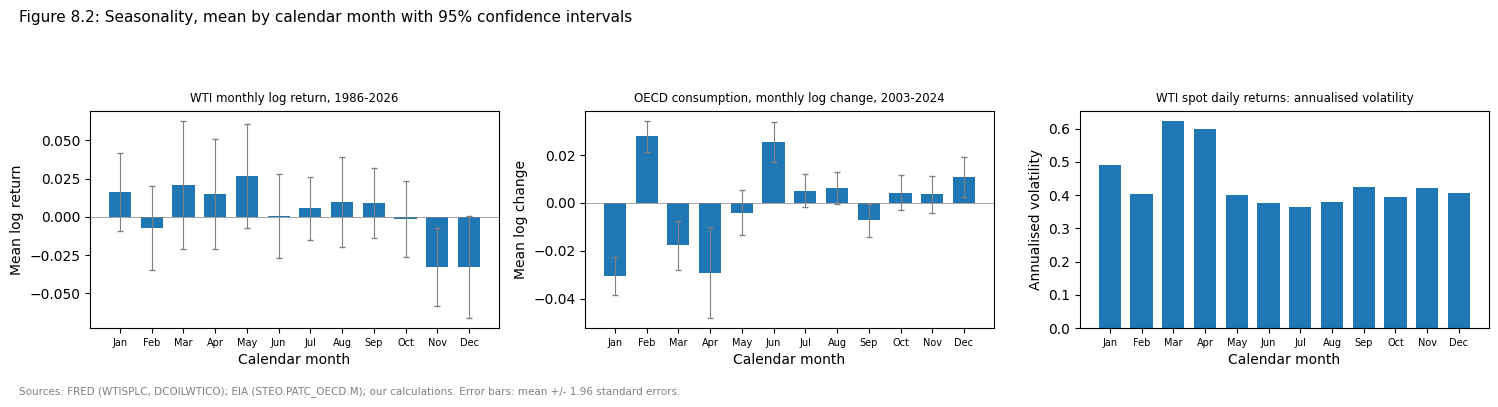

Table 8.6: Seasonality tests across the 12 calendar months


,statistic,p-value
"WTI monthly return, Kruskal-Wallis H",20.96,0.0338
"WTI monthly return, ANOVA F",1.564,0.1062
"S&P 500 monthly return, Kruskal-Wallis H",12.75,0.3098
"OECD consumption change, Kruskal-Wallis H",115.4,1.549e-19
"WTI daily |return|, Kruskal-Wallis H",15.36,0.1668


In [44]:
mret, spx_mret = rm["WTI monthly (avg)"], rm["S&P 500 monthly (avg)"]
cons = chg_m["STEO.PATC_OECD.M"]
by_month = lambda s: [s[s.index.month == m] for m in range(1, 13)]
kw_w, an_w = stats.kruskal(*by_month(mret)), stats.f_oneway(*by_month(mret))
kw_s, kw_c = stats.kruskal(*by_month(spx_mret)), stats.kruskal(*by_month(cons))
kw_v = stats.kruskal(*by_month(rd["DCOILWTICO"].abs()))
vol_by_month = rd["DCOILWTICO"].groupby(rd["DCOILWTICO"].index.month).std() * np.sqrt(252)

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
for ax, ser, ttl, ylab in [(axes[0], mret, f"WTI monthly log return, {mret.index.min():%Y}-{mret.index.max():%Y}", "Mean log return"),
                           (axes[1], cons, f"OECD consumption, monthly log change, {cons.index.min():%Y}-{cons.index.max():%Y}", "Mean log change")]:
    g = ser.groupby(ser.index.month)
    ax.bar(range(1, 13), g.mean().values, color="tab:blue", width=0.7)
    ax.errorbar(range(1, 13), g.mean().values, yerr=1.96 * (g.std() / np.sqrt(g.size())).values, fmt="none", ecolor="grey", elinewidth=0.8, capsize=2)
    ax.axhline(0, color="grey", lw=0.5)
    ax.set_title(ttl, fontsize=8.5)
    ax.set_ylabel(ylab)
axes[2].bar(range(1, 13), vol_by_month.values, color="tab:blue", width=0.7)
axes[2].set_title("WTI spot daily returns: annualised volatility", fontsize=8.5)
axes[2].set_ylabel("Annualised volatility")
for ax in axes:
    ax.set_xticks(range(1, 13))
    ax.set_xticklabels(months, fontsize=7)
    ax.set_xlabel("Calendar month")
finish(fig, "Figure 8.2: Seasonality, mean by calendar month with 95% confidence intervals",
       "Sources: FRED (WTISPLC, DCOILWTICO); EIA (STEO.PATC_OECD.M); our calculations. Error bars: mean +/- 1.96 standard errors.")
print("Table 8.6: Seasonality tests across the 12 calendar months")
pd.DataFrame({"statistic": [kw_w.statistic, an_w.statistic, kw_s.statistic, kw_c.statistic, kw_v.statistic],
              "p-value": [kw_w.pvalue, an_w.pvalue, kw_s.pvalue, kw_c.pvalue, kw_v.pvalue]},
             index=["WTI monthly return, Kruskal-Wallis H", "WTI monthly return, ANOVA F", "S&P 500 monthly return, Kruskal-Wallis H",
                    "OECD consumption change, Kruskal-Wallis H", "WTI daily |return|, Kruskal-Wallis H"]).map(lambda v: f"{v:.4g}")

**Interpretation.** Figure 8.2 and Table 8.6 show seasonality in the physical market but only weak evidence of it in the price. OECD consumption changes differ strongly by calendar month (H = 115.4, p = 1.6e-19). For WTI monthly returns the evidence is mixed: the rank-based Kruskal-Wallis test rejects equal distributions at the 5% level (p = 0.034), but the ANOVA test of equal means does not (p = 0.106), and the size of daily WTI returns does not differ significantly across months (p = 0.17). The S&P 500 shows no calendar-month effect (p = 0.31). We therefore do not treat price seasonality as established.

**Answer 8a.** Set against the S&P 500 benchmark, oil prices look different in four ways:

* **Much higher volatility and larger spikes.** Annualised daily volatility is 0.45 for WTI spot against 0.18 for the S&P 500 (Table 8.2), and the largest one-day oil moves are nearly twice the largest equity move (Table 8.4).
* **A price that can go negative.** WTI spot and futures both closed below zero on 20 April 2020 (Table 5.7), which an equity index cannot do.
* **Extreme volatility regimes.** WTI's rolling volatility reaches several times its median in spring 2020 (Table 7.1, Figure 7.6).
* **Seasonality in quantities rather than prices.** Oil consumption is strongly seasonal, but the evidence for seasonality in the oil price is weak and inconsistent (Table 8.6).

Fat tails, volatility clustering and non-stationary price levels are shared with the equity benchmark (Tables 8.2, 8.3 and 8.5); oil differs in their magnitude.

### Step 8d: Other stylized facts about oil prices

We checked three further properties: whether tails thin as returns are aggregated over longer horizons, whether volatility rises more after falls than after rises (the leverage effect), and how closely futures track the spot price.

In [45]:
v1 = rd["DCOILWTICO"]
agg = {}
for h, lab in [(1, "1 day"), (5, "5 days"), (21, "21 days"), (63, "63 days")]:
    blocks = np.arange(len(v1)) // h
    r_h = v1.groupby(blocks).sum()[v1.groupby(blocks).size() == h]
    agg[lab] = {"n": len(r_h), "skewness": stats.skew(r_h), "excess kurtosis": stats.kurtosis(r_h), "JB p": stats.jarque_bera(r_h).pvalue}
print("Table 8.7: WTI spot returns aggregated over non-overlapping horizons")
print(pd.DataFrame(agg).T.round(4).to_string())

lev = {D_LABEL[k]: {f"lag {l}": rd[k].corr(rd[k].abs().shift(-l)) for l in [1, 5, 10, 20]} for k in ["DCOILWTICO", "^GSPC"]}
print("\nTable 8.8: Correlation of r(t) with |r(t+lag)|")
print(pd.DataFrame(lev).T.round(4).to_string())

bas = (A["CL=F"] - A["DCOILWTICO"])[~A.index.isin(roll_days)].dropna()
print(f"\nFutures minus spot on non-roll days (USD/bbl): median {bas.median():.3f}, 5th percentile {bas.quantile(0.05):.2f}, 95th percentile {bas.quantile(0.95):.2f}")

Table 8.7: WTI spot returns aggregated over non-overlapping horizons
              n  skewness  excess kurtosis  JB p
1 day    9514.0   -0.1643          22.9157   0.0
5 days   1902.0    0.0772          12.6682   0.0
21 days   453.0    1.3690          15.0994   0.0
63 days   151.0    0.0412           3.7290   0.0

Table 8.8: Correlation of r(t) with |r(t+lag)|
                      lag 1   lag 5  lag 10  lag 20
WTI spot            -0.0199 -0.0115 -0.0334 -0.0458
S&P 500 (benchmark) -0.1242 -0.0928 -0.0717 -0.0517

Futures minus spot on non-roll days (USD/bbl): median -0.000, 5th percentile -1.10, 95th percentile 0.44


**Answer 8d.** The outputs support three further stylized facts:

* **Tails thin with aggregation, but slowly and unevenly.** Table 8.7 shows excess kurtosis of 22.9 at one day, 12.7 at five days, 15.1 at 21 days and 3.7 at 63 days, with normality rejected at every horizon. The 21-day value is raised by the block covering March and April 2020.
* **A weak leverage effect.** Table 8.8 shows that today's WTI return is only weakly negatively correlated with future absolute returns (−0.02 at lag 1, −0.05 at lag 20), while the S&P 500 effect is clearly stronger (−0.12 at lag 1). Falls in oil prices raise future volatility only slightly more than rises do.
* **A tight spot-futures link with occasional gaps.** Outside roll days the median futures-minus-spot difference is zero and 90% of days lie between −1.10 and +0.44 dollars per barrel (output above), and daily returns correlate at 0.93 (Step 5c). Spot-only jumps such as 31 March 2020 are the exception (Table 5.3b).

Together with the unstable cross-market relations in Tables 7.3a and 7.3b and the outlier-driven correlations in Figure 7.8, these facts have practical consequences, which are our judgement. Risk measures based on a normal distribution will understate how often extreme oil moves occur (Table 8.2). Exposure should be scaled to recent volatility, because volatility clusters and persists (Table 8.3, Figure 8.1). Relationships estimated on one period should not be assumed to hold in the next, which supports Alvi's case for re-learning the network as new data arrive (Alvi, 2018). Finally, Alvi's up/down coding of monthly changes (Alvi, 2018) discards the size of moves, which is exactly where oil differs most from other assets.

## References

- Akaike, H. (1974). A new look at the statistical model identification. *IEEE Transactions on Automatic Control, 19*(6), 716–723. https://doi.org/10.1109/TAC.1974.1100705
- Alvi, D. A. (2018). *Application of probabilistic graphical models in forecasting crude oil price* [Bachelor's dissertation, University College London]. arXiv. https://arxiv.org/abs/1804.10869
- Board of Governors of the Federal Reserve System. (2021). *Industrial production: Mining, quarrying, and oil and gas extraction: Crude oil (NAICS = 211111pt.) (DISCONTINUED) [IPG211111CN]* [Data set]. FRED, Federal Reserve Bank of St. Louis. Retrieved October 8, 2026, from https://fred.stlouisfed.org/series/IPG211111CN
- Board of Governors of the Federal Reserve System. (2026a). *Capacity utilization: Mining: Oil and gas extraction (NAICS = 211) [CAPUTLG211S]* [Data set]. FRED, Federal Reserve Bank of St. Louis. Retrieved October 8, 2026, from https://fred.stlouisfed.org/series/CAPUTLG211S
- Board of Governors of the Federal Reserve System. (2026b). *Industrial capacity: Mining: Oil and gas extraction (NAICS = 211) [CAPG211S]* [Data set]. FRED, Federal Reserve Bank of St. Louis. Retrieved October 8, 2026, from https://fred.stlouisfed.org/series/CAPG211S
- Board of Governors of the Federal Reserve System. (2026c). *Industrial production: Mining: Crude oil (NAICS = 21112) [IPG21112S]* [Data set]. FRED, Federal Reserve Bank of St. Louis. Retrieved October 8, 2026, from https://fred.stlouisfed.org/series/IPG21112S
- Board of Governors of the Federal Reserve System. (2026d). *Industrial production: Mining: Drilling oil and gas wells (NAICS = 213111) [IPN213111N]* [Data set]. FRED, Federal Reserve Bank of St. Louis. Retrieved October 8, 2026, from https://fred.stlouisfed.org/series/IPN213111N
- Board of Governors of the Federal Reserve System. (2026e). *Industrial production: Mining: Oil and gas extraction (NAICS = 211) [IPG211S]* [Data set]. FRED, Federal Reserve Bank of St. Louis. Retrieved October 8, 2026, from https://fred.stlouisfed.org/series/IPG211S
- Board of Governors of the Federal Reserve System. (2026f). *Industrial production: Total index [INDPRO]* [Data set]. FRED, Federal Reserve Bank of St. Louis. Retrieved October 8, 2026, from https://fred.stlouisfed.org/series/INDPRO
- Caldara, D., & Iacoviello, M. (2022). Measuring geopolitical risk. *American Economic Review, 112*(4), 1194–1225. https://doi.org/10.1257/aer.20191823
- Caldara, D., & Iacoviello, M. (2026). *Geopolitical risk (GPR) index* [Data set]. Retrieved October 8, 2026, from https://www.matteoiacoviello.com/gpr.htm
- Cont, R. (2001). Empirical properties of asset returns: Stylized facts and statistical issues. *Quantitative Finance, 1*(2), 223–236. https://doi.org/10.1080/713665670
- Dickey, D. A., & Fuller, W. A. (1979). Distribution of the estimators for autoregressive time series with a unit root. *Journal of the American Statistical Association, 74*(366a), 427–431. https://doi.org/10.1080/01621459.1979.10482531
- Engle, R. F. (1982). Autoregressive conditional heteroscedasticity with estimates of the variance of United Kingdom inflation. *Econometrica, 50*(4). https://doi.org/10.2307/1912773
- Federal Reserve Bank of St. Louis. (2026). *Spot crude oil price: West Texas Intermediate (WTI) [WTISPLC]* [Data set]. FRED, Federal Reserve Bank of St. Louis. Retrieved October 8, 2026, from https://fred.stlouisfed.org/series/WTISPLC
- Jarque, C. M., & Bera, A. K. (1987). A test for normality of observations and regression residuals. *International Statistical Review, 55*(2). https://doi.org/10.2307/1403192
- Kruskal, W. H., & Wallis, W. A. (1952). Use of ranks in one-criterion variance analysis. *Journal of the American Statistical Association, 47*(260), 583–621. https://doi.org/10.1080/01621459.1952.10483441
- Kwiatkowski, D., Phillips, P. C. B., Schmidt, P., & Shin, Y. (1992). Testing the null hypothesis of stationarity against the alternative of a unit root. *Journal of Econometrics, 54*(1–3), 159–178. https://doi.org/10.1016/0304-4076(92)90104-Y
- Ljung, G. M., & Box, G. E. P. (1978). On a measure of lack of fit in time series models. *Biometrika, 65*(2), 297–303. https://doi.org/10.1093/biomet/65.2.297
- NIST/SEMATECH. (n.d.). 1.3.5.17. Detection of outliers. In *NIST/SEMATECH e-handbook of statistical methods*. National Institute of Standards and Technology. Retrieved October 8, 2026, from https://www.itl.nist.gov/div898/handbook/eda/section3/eda35h.htm
- U.S. Bureau of Labor Statistics. (2026a). *Consumer price index for all urban consumers: Energy in U.S. city average [CPIENGSL]* [Data set]. FRED, Federal Reserve Bank of St. Louis. Retrieved October 8, 2026, from https://fred.stlouisfed.org/series/CPIENGSL
- U.S. Bureau of Labor Statistics. (2026b). *Producer price index by industry: Oil and gas extraction [PCU211211]* [Data set]. FRED, Federal Reserve Bank of St. Louis. Retrieved October 8, 2026, from https://fred.stlouisfed.org/series/PCU211211
- U.S. Energy Information Administration. (n.d.-a). *API technical documentation*. Retrieved October 8, 2026, from https://www.eia.gov/opendata/documentation.php
- U.S. Energy Information Administration. (n.d.-b). *Short-Term Energy Outlook: Data series changes*. Retrieved October 8, 2026, from https://www.eia.gov/outlooks/steo/report/changes.php
- U.S. Energy Information Administration. (n.d.-c). *U.S. imports from OPEC countries of crude oil [PET.MCRIMXX2.M]* [Data set]. EIA Open Data API v2. Retrieved October 8, 2026, from https://api.eia.gov/v2/seriesid/PET.MCRIMXX2.M
- U.S. Energy Information Administration. (2021, January 12). *Short-Term Energy Outlook notice*. https://www.eia.gov/outlooks/steo/archives/notice_data_01_12_2021.php
- U.S. Energy Information Administration. (2026a). *Crude oil prices: Brent - Europe [DCOILBRENTEU]* [Data set]. FRED, Federal Reserve Bank of St. Louis. Retrieved October 8, 2026, from https://fred.stlouisfed.org/series/DCOILBRENTEU
- U.S. Energy Information Administration. (2026b). *Crude oil prices: West Texas Intermediate (WTI) - Cushing, Oklahoma [DCOILWTICO]* [Data set]. FRED, Federal Reserve Bank of St. Louis. Retrieved October 8, 2026, from https://fred.stlouisfed.org/series/DCOILWTICO
- U.S. Energy Information Administration. (2026c). *Short-Term Energy Outlook (STEO)* [Data set]. EIA Open Data API v2 and STEO bulk file. Retrieved October 8, 2026, from https://www.eia.gov/opendata/bulk/STEO.zip
- Yahoo Finance. (n.d.-a). *Crude oil (CL=F)* [Data set]. Retrieved October 8, 2026, from https://finance.yahoo.com/quote/CL=F
- Yahoo Finance. (n.d.-b). *S&P 500 (^GSPC)* [Data set]. Retrieved October 8, 2026, from https://finance.yahoo.com/quote/%5EGSPC